# Conditional regional field synthesis: Zhuang MERFISH

Primary workflow: import, regional setup, explicit regional fit/checkpoint load, regional evaluation and interpolation. The field emits splats from anatomical level and donor embedding; emitted fields are not refitted to interpolation targets. This is an in-sample synthesis demonstration using two donors, not evidence of new-animal generation.

The archived measurement-level reconstruction is retained as a baseline. Occupancy is an optional subsequent stage using the same regional expression objective. Both training stages are opt-in; missing checkpoints never start training.


In [1]:
from pathlib import Path
import sys, json, hashlib, random, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / 'pyproject.toml').exists() and (PROJECT_ROOT / 'spatsplat').is_dir()):
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError('Cannot locate repository root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from paper.data_loaders.zhuang_mouse_brain import ZhuangMouseBrainAtlas, DEFAULT_MANIFEST, data_directory
from paper.cohort_field_synthesis import align_sections, CohortSplatGenerator, fit_cohort, fit_cohort_curriculum
from paper.conditional_field import initialize_from_observations, predict_field, field_metrics, export_field
from spatsplat.autoencoder import GeneProfileAutoencoder, train_profile_autoencoder, evaluate_profile_autoencoder
pd.options.display.float_format = lambda x: f'{x:.4g}'
np.set_printoptions(precision=4)

# Historical point-level experiments remain opt-in; use the regional workflow below.
RUN_EXPRESSION_EXPERIMENT = True


## Primary experiment: regional field synthesis

The target is a faithful regional expression field, not recovery of every noisy measurement or eight hard point-profile labels. This stage fine-tunes the archived frozen-decoder generator with **50, 100 and 200 um regional means**, using the exact physical bins from the regional-fidelity diagnostic. Means are taken over published log2 expression; they are not raw-count pseudobulk or area integrals. Empty bins are missing, not biological zeros.

Each update chooses a section and scale uniformly, then four eligible regions uniformly. It renders at **every observed coordinate within each selected region** before averaging. Cosine, MAE and log-total losses compare those regional means. There is no center-only approximation, cluster-frequency constraint or default point-level loss. Chunking limits each renderer call, not region membership.

This controlled first fit retains the archived frozen geometry mapping and decoder, tuning the molecular emission network. It does not demonstrate that geometry is optimal. The original point-supervised generator is the baseline. All six endpoint sections are training examples; neither endpoint metrics nor donor interpolation establish generalization to new animals.

Run the import cell, then these regional cells. Set `RUN_REGIONAL_TRAINING=True` for the first fit; otherwise completed checkpoints load and cache misses never train. The older point-level experiments below remain disabled. Occupancy is retained as an optional later stage (`ENABLE_OCCUPANCY=False` by default) and must start from a completed regional fit.


In [2]:
from paper.cohort_regional_synthesis import load_source, prepare_regions, RegionalObjective, fit_regional
from paper.zhuang_regional_fidelity import fit_reference, evaluate_regions, real_real_controls
from paper.zhuang_regional_fidelity import profiles as regional_profiles
from matplotlib.colors import ListedColormap
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch

REG_SOURCE_RUN = '6fa020a20e5d'
RUN_REGIONAL_TRAINING = True
FORCE_REGIONAL_RETRAIN = False
ENABLE_OCCUPANCY = True
REG_CFG = dict(steps=5000, lr=1e-3, log_every=250, seed=3107,
    widths_um=[50, 100, 200], regions_per_step=4, render_batch_size=512,
    min_measurements=5, mae_weight=1., cosine_weight=1., total_weight=0.1,
    point_weight=0.)
REG_REFERENCE_WIDTH = 100
REG_MARKERS = ['Cldn11', 'Mog', 'Slc17a7', 'Gad2', 'Gja1', 'Ctss']
REG_MAP_GENES = ['Cldn11', 'Slc17a7']
REG_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b']
REG_ALPHAS = [0., 0.25, 0.5, 0.75, 1.]
REG_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
reg_source = data_directory()/'processed'/'zhuang_conditional_synthesis'/REG_SOURCE_RUN
reg_source_checkpoint = PROJECT_ROOT/'notebooks'/'checkpoints'/'zhuang_conditional_synthesis'/REG_SOURCE_RUN/'frozen'/'generator_latest.pt'
reg_base, reg_records, reg_genes, reg_symbols, reg_settings, reg_sources = load_source(reg_source, reg_source_checkpoint)
reg_base = reg_base.to(REG_DEVICE).eval()
reg_regions = prepare_regions(reg_records, REG_CFG['widths_um'], REG_CFG['min_measurements'])
reg_objective = RegionalObjective(reg_regions, REG_CFG)
reg_reference_sections = [pair[0] for pair in reg_settings['pairs']]
# Same observed data, ordering, seed and settings as diagnostic-regional_fidelity.
# Generated fields never enter the reference; R0-R4 are not the old P0-P7 labels.
reg_reference = fit_reference(reg_regions, REG_REFERENCE_WIDTH, reg_reference_sections,
    n_components=8, n_programs=5, seed=3107)
reg_sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
reg_provenance = dict(source_run=REG_SOURCE_RUN, config=REG_CFG,
    geometry='archived frozen mapping', decoder='frozen', reference_width_um=REG_REFERENCE_WIDTH,
    reference_sections=reg_reference_sections, n_programs=5, pca_dim=8, reference_seed=3107,
    sources={str(p): reg_sha(p) for p in reg_sources},
    code={name: reg_sha(PROJECT_ROOT/name) for name in [
        'paper/cohort_regional_synthesis.py', 'paper/cohort_field_synthesis.py',
        'paper/zhuang_regional_fidelity.py', 'paper/conditional_field.py', 'spatsplat/models.py']},
    torch_version=str(torch.__version__))
REG_RUN = hashlib.sha256(json.dumps(reg_provenance, sort_keys=True).encode()).hexdigest()[:12]
REG_OUTPUT = data_directory()/'processed'/'zhuang_regional_synthesis'/REG_RUN
REG_FIGURES = PROJECT_ROOT/'figures'/'zhuang_regional_synthesis'/REG_RUN
REG_CHECKPOINT = PROJECT_ROOT/'notebooks'/'checkpoints'/'zhuang_regional_synthesis'/REG_RUN/'generator.pt'
for directory in [REG_OUTPUT, REG_FIGURES, REG_CHECKPOINT.parent]:
    directory.mkdir(parents=True, exist_ok=True)
(REG_OUTPUT/'manifest.json').write_text(json.dumps(reg_provenance, indent=2))
np.savez_compressed(REG_OUTPUT/'evaluation_reference.npz', gene_ids=reg_genes,
    pca_mean=reg_reference['pca'].mean_, pca_components=reg_reference['pca'].components_,
    pca_explained_variance=reg_reference['pca'].explained_variance_,
    state_centers=reg_reference['programs'].cluster_centers_, training_mean=reg_reference['mean_expression'])
reg_marker_indices = {}
for gene in REG_MARKERS:
    positions = np.flatnonzero(reg_symbols == gene)
    if len(positions) != 1:
        raise ValueError(f'Expected one marker match: {gene}')
    reg_marker_indices[gene] = int(positions[0])
background = regional_profiles(reg_reference['mean_expression'][None])[0]
reg_legend = pd.DataFrame([dict(state=f'R{k}', color=REG_COLORS[k], enriched_genes=', '.join(
    reg_symbols[np.argsort((center-background)/(background+1e-5))[-5:][::-1]]))
    for k, center in enumerate(reg_reference['programs'].cluster_centers_)])
reg_legend.to_csv(REG_OUTPUT/'regional_state_legend.csv', index=False)
display(reg_legend)
reg_coverage = pd.DataFrame([dict(section=s, width_um=w, regions=len(g['counts']), coverage=g['coverage'])
    for (s, w), g in reg_regions.items()])
reg_coverage.to_csv(REG_OUTPUT/'coverage.csv', index=False)
display(reg_coverage)
if (reg_coverage.coverage < 0.5).any():
    print('Some scales cover fewer than half the measurements. Those losses/metrics describe denser eligible regions, not the whole section.')
print(f'Regional run: {REG_RUN}; device: {REG_DEVICE}. Training is opt-in.')


,state,color,enriched_genes
0,R0,#1f77b4,"Satb2, Neurod2, Igfn1, Neurod6, Slc30a3"
1,R1,#ff7f0e,"Ermn, Tnfaip6, St18, Mog, C030029H02Rik"
2,R2,#2ca02c,"Osr1, Dcn, Igf2, Ranbp3l, Serpinf1"
3,R3,#9467bd,"Shox2, Dlk1, Irs4, Gabrq, Dgkk"
4,R4,#8c564b,"Drd2, Syndig1l, Lrrc10b, Serpina9, Adora2a"


,section,width_um,regions,coverage
0,Zhuang-ABCA-1.041,50,599,0.285
1,Zhuang-ABCA-1.041,100,1177,0.9612
2,Zhuang-ABCA-1.041,200,355,0.9983
3,Zhuang-ABCA-2.019,50,845,0.387
4,Zhuang-ABCA-2.019,100,1106,0.9611
5,Zhuang-ABCA-2.019,200,345,0.9952
6,Zhuang-ABCA-1.059,50,1436,0.3554
7,Zhuang-ABCA-1.059,100,1994,0.9825
8,Zhuang-ABCA-1.059,200,554,0.9979
9,Zhuang-ABCA-2.028,50,2300,0.463


Some scales cover fewer than half the measurements. Those losses/metrics describe denser eligible regions, not the whole section.
Regional run: b986da24868d; device: cuda. Training is opt-in.


Loaded completed regional fit; no training.


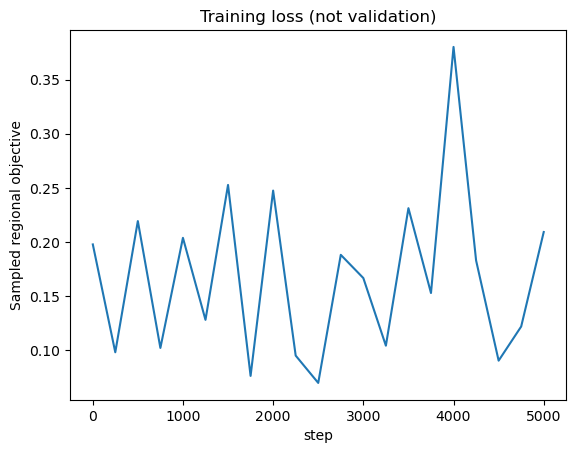

In [3]:
reg_ready = False
reg_model = copy.deepcopy(reg_base)
reg_history = pd.DataFrame()
if REG_CHECKPOINT.exists() and not (RUN_REGIONAL_TRAINING and FORCE_REGIONAL_RETRAIN):
    reg_saved = torch.load(REG_CHECKPOINT, map_location='cpu', weights_only=True)
    if reg_saved['provenance'] != reg_provenance:
        raise ValueError('Regional checkpoint provenance mismatch')
    if reg_saved.get('complete', False):
        reg_model.load_state_dict(reg_saved['state_dict'])
        reg_history = pd.DataFrame(reg_saved['history'])
        reg_ready = True
        print('Loaded completed regional fit; no training.')
if RUN_REGIONAL_TRAINING and (not reg_ready or FORCE_REGIONAL_RETRAIN):
    torch.manual_seed(REG_CFG['seed'])
    reg_model = copy.deepcopy(reg_base)
    def save_regional(model, history, complete=False):
        temporary = REG_CHECKPOINT.with_suffix('.tmp')
        torch.save(dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()},
            provenance=reg_provenance, history=history, complete=complete), temporary)
        temporary.replace(REG_CHECKPOINT)
    reg_history = fit_regional(reg_model, reg_records, reg_objective, REG_CFG,
        on_checkpoint=save_regional)
    save_regional(reg_model, reg_history.to_dict('records'), complete=True)
    reg_ready = True
reg_model.eval()
if not reg_ready:
    print('No completed regional fit. Set RUN_REGIONAL_TRAINING=True to train explicitly.')
elif len(reg_history):
    reg_history.to_csv(REG_OUTPUT/'history.csv', index=False)
    ax = reg_history.plot(x='step', y='sampled_regional_loss', legend=False)
    ax.set(ylabel='Sampled regional objective', title='Training loss (not validation)')
    plt.show()


profile_cosine  expression_mae  profile_l1  \
width_um method                                                                 
50       Point objective baseline          0.8354         0.08606      0.7379   
         Regional objective                0.8299         0.09079      0.7631   
         Spatial shuffle (oracle)          0.4701          0.1491       1.248   
         Training mean                     0.6528          0.1242        1.04   
100      Point objective baseline          0.8832         0.07052      0.6037   
         Regional objective                0.8767         0.07398      0.6176   
         Spatial shuffle (oracle)          0.5744          0.1279       1.062   
         Training mean                     0.7275          0.1027      0.8548   
200      Point objective baseline          0.9419         0.04765      0.4185   
         Regional objective                0.9348         0.04938      0.4185   
         Spatial shuffle (oracle)          0.6605          0.1024      0.8588   
         Training mean                     0.7792         0.08188      0.6866   

                                    frechet  
width_um method                              
50       Point objective baseline 9.529e-05  
         Regional objective       8.994e-05  
         Spatial shuffle (oracle) 8.674e-19  
         Training mean             0.002095  
100      Point objective baseline 7.016e-05  
         Regional objective       4.644e-05  
         Spatial shuffle (oracle) 1.807e-19  
         Training mean             0.001393  
200      Point objective baseline 6.479e-05  
         Regional objective       1.823e-05  
         Spatial shuffle (oracle)         0  
         Training mean             0.001132

Equal-section summaries; inspect section-level CSVs and coverage before interpreting averages.


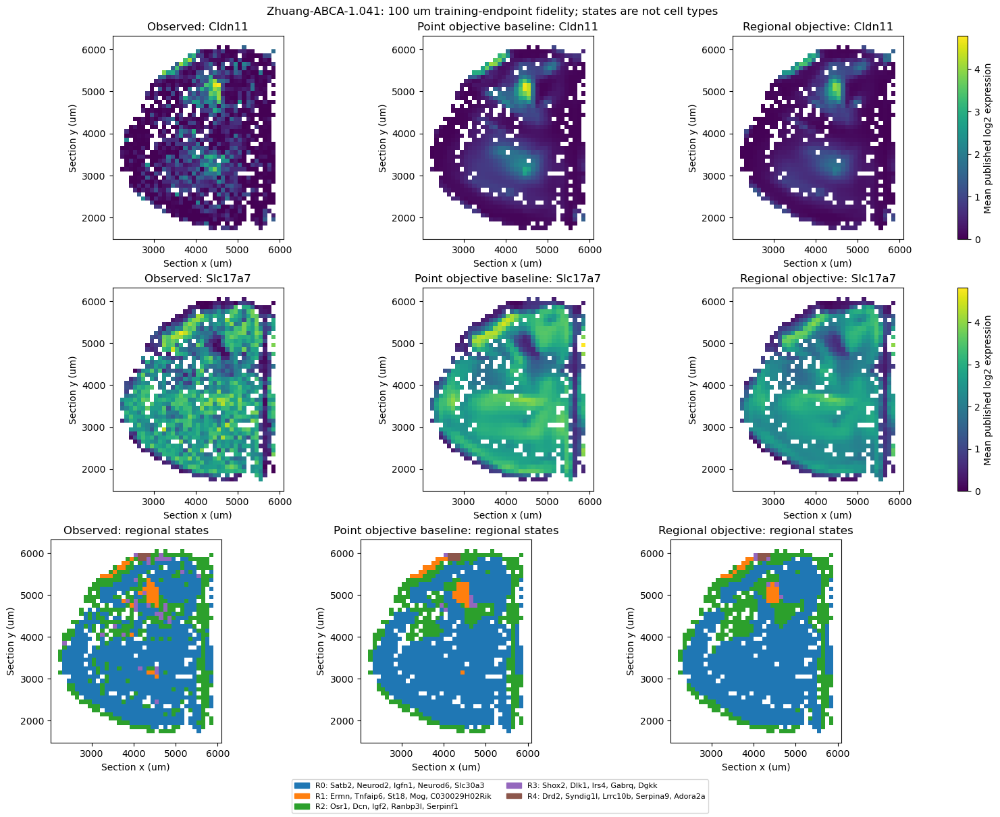

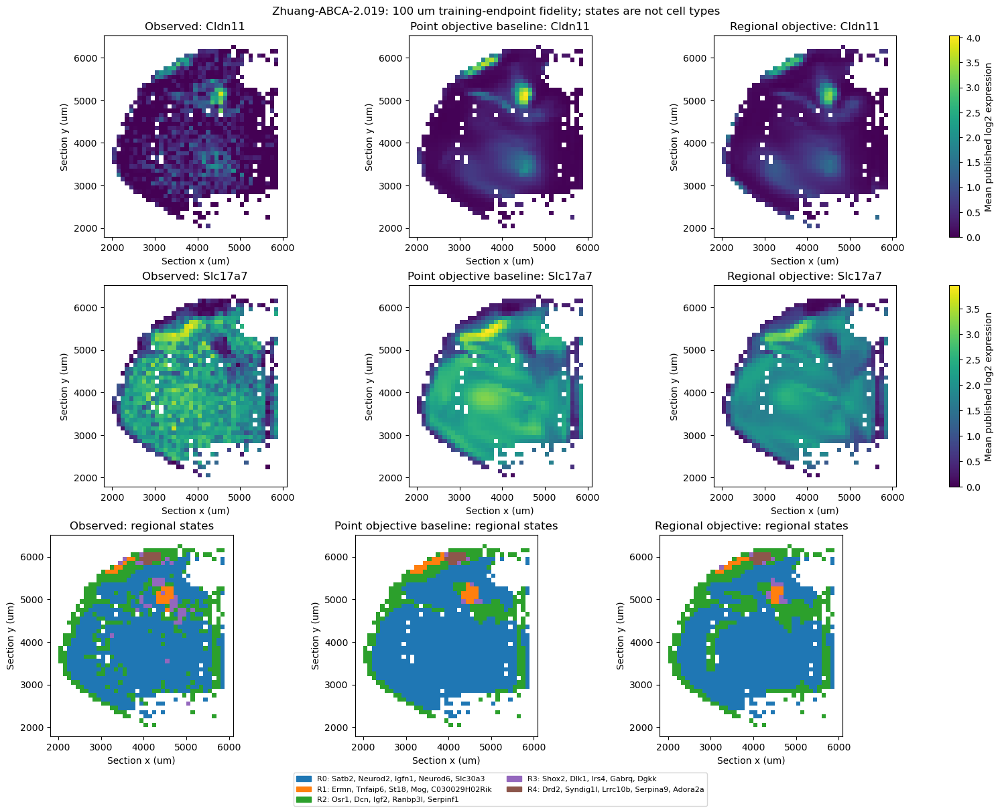

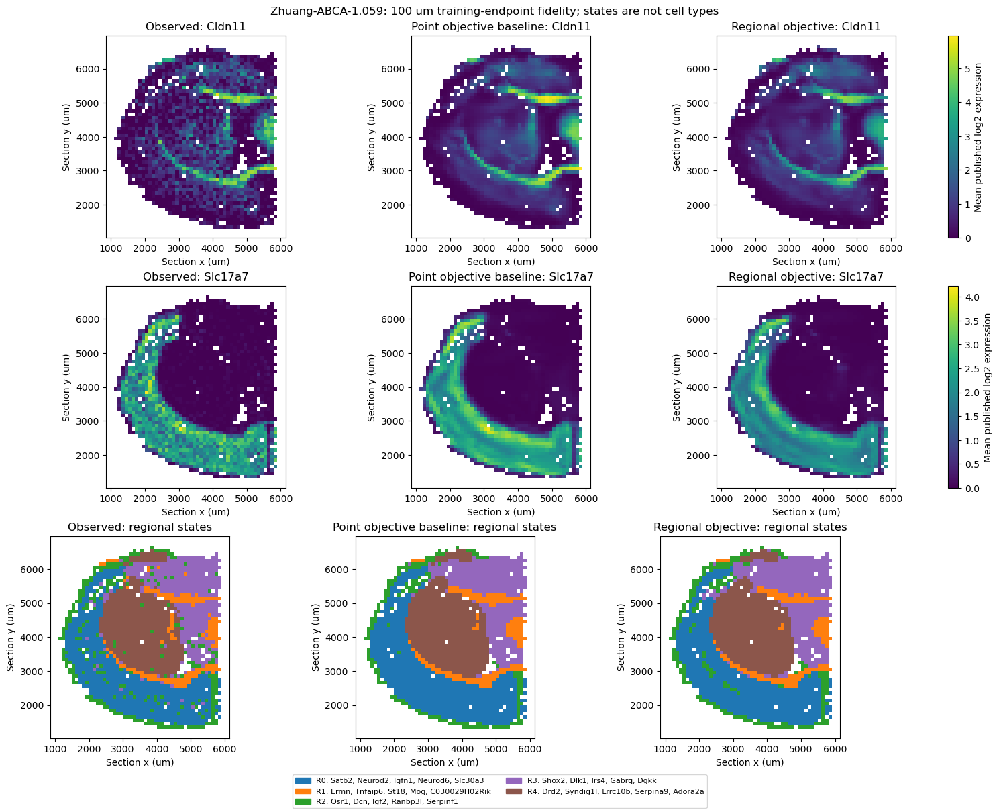

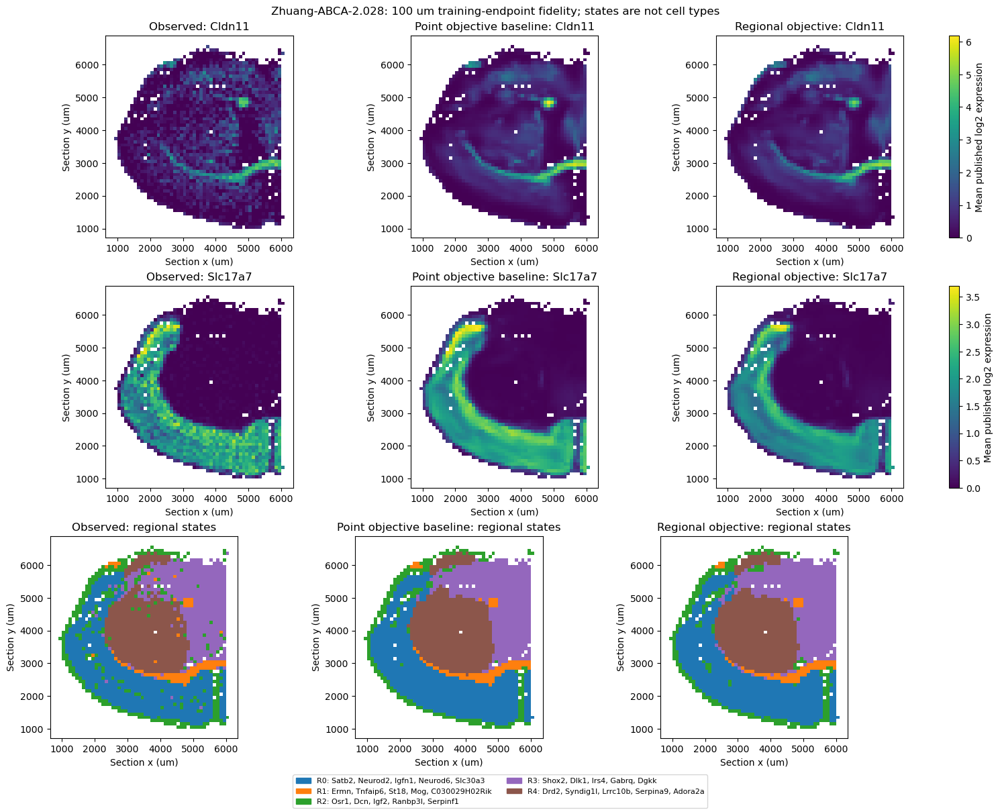

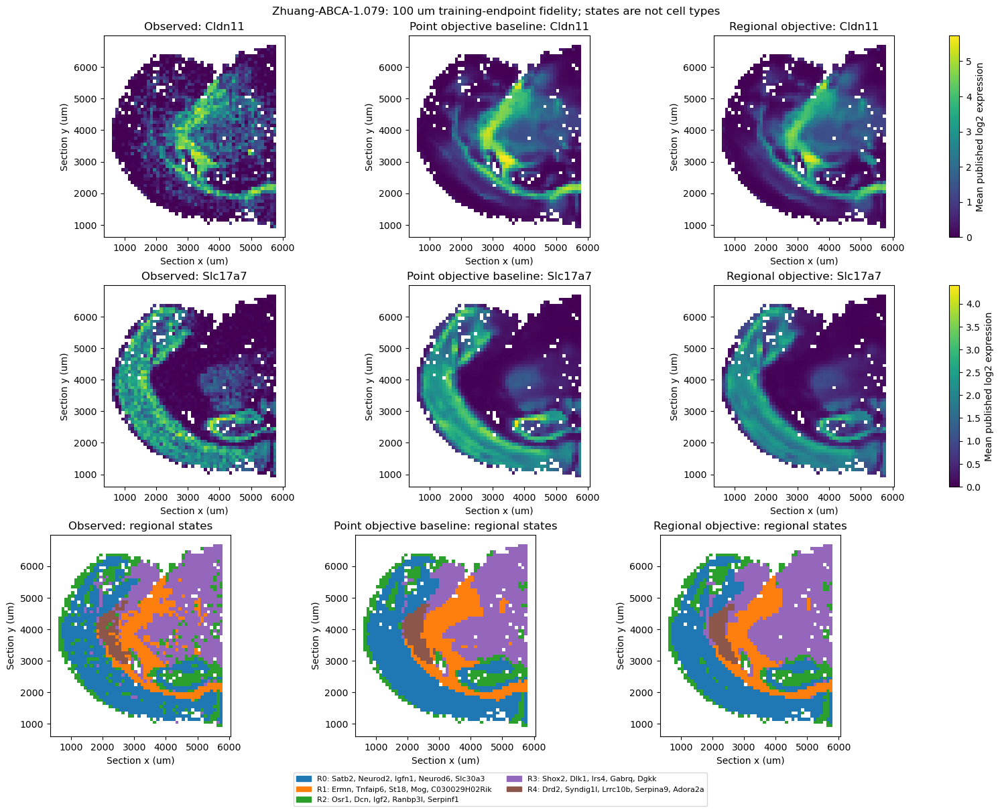

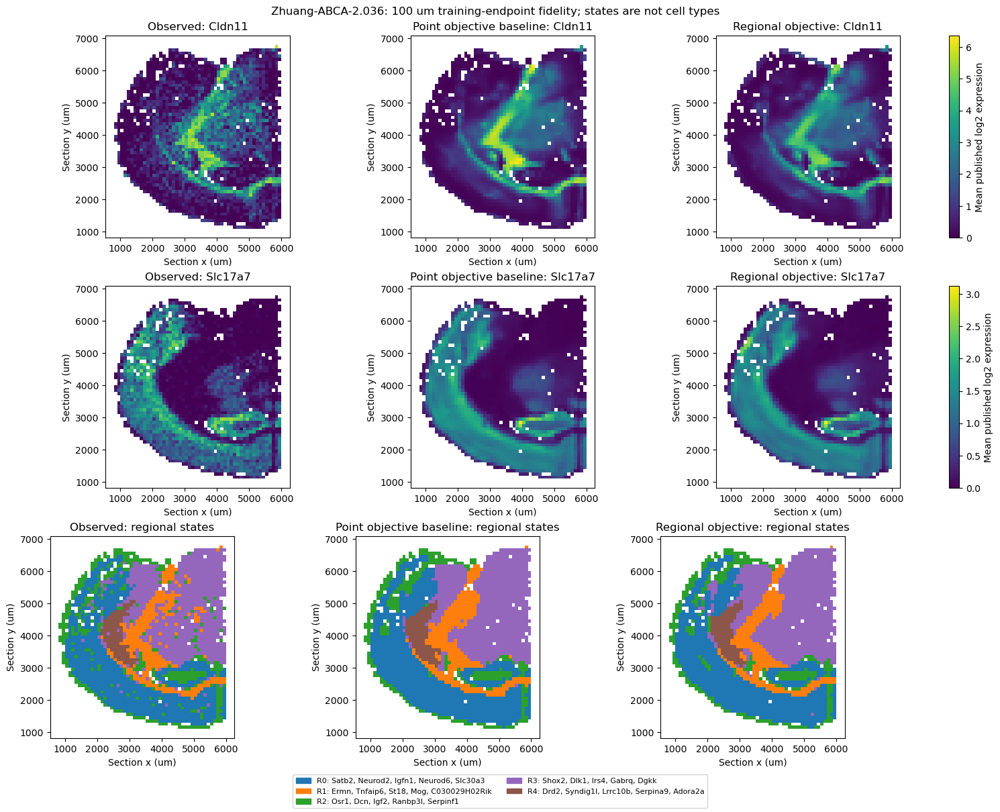

In [4]:
def evaluate_regional_models(models, output):
    from paper.zhuang_regional_fidelity import profiles as regional_profiles
    # Exact aggregation uses the same regions and all measurement coordinates for every method.
    evaluated = {key: dict(g, values=dict(g['values'])) for key, g in reg_regions.items()}
    for name, model in models.items():
        endpoint_predictions = {}
        for r in reg_records:
            prediction = predict_field(model, r['xy'], r['condition'], batch_size=REG_CFG['render_batch_size'])
            endpoint_predictions[r['section']] = prediction
            for width in REG_CFG['widths_um']:
                g = evaluated[r['section'], width]
                g['values'][name] = np.asarray(g['operator'] @ prediction)
        np.savez_compressed(output/(name.lower().replace(' ', '_')+'_endpoints.npz'),
            gene_ids=reg_genes, **endpoint_predictions)
    frames, marker_frames, state_rows = [], [], []
    for (section, width), g in evaluated.items():
        metrics, markers, _ = evaluate_regions(g, reg_reference, reg_marker_indices, seed=3107)
        frames.append(metrics.assign(section=section, width_um=width))
        marker_frames.append(markers.assign(section=section, width_um=width))
        observed_states = reg_reference['programs'].predict(regional_profiles(g['values']['Observed']))
        observed_fraction = np.bincount(observed_states, minlength=5)/len(observed_states)
        for name, values in g['values'].items():
            states = reg_reference['programs'].predict(regional_profiles(values))
            fraction = np.bincount(states, minlength=5)/len(states)
            for k in range(5):
                state_rows.append(dict(section=section, width_um=width, method=name, state=f'R{k}',
                    region_fraction=fraction[k], observed_fraction=observed_fraction[k],
                    matched_state_agreement=float(np.mean(states == observed_states)),
                    fraction_total_variation=float(np.abs(fraction-observed_fraction).sum()/2)))
        np.savez_compressed(output/f'{section}_{width}um.npz', centers_um=g['centers_um'],
            counts=g['counts'], gene_ids=reg_genes, **g['values'])
    metrics = pd.concat(frames, ignore_index=True)
    metrics.to_csv(output/'regional_metrics.csv', index=False)
    pd.concat(marker_frames, ignore_index=True).to_csv(output/'regional_marker_metrics.csv', index=False)
    pd.DataFrame(state_rows).to_csv(output/'regional_state_distributions.csv', index=False)
    controls = real_real_controls(evaluated, {w: reg_reference for w in REG_CFG['widths_um']},
        reg_settings['pairs'], REG_CFG['widths_um'], seed=3107)
    controls.to_csv(output/'matched_size_frechet_controls.csv', index=False)
    return evaluated, metrics

def draw_regional_map(ax, region, width, values, cmap='viridis', vmin=None, vmax=None):
    vertices = region['centers_um'][:, None]+width/2*np.array([[-1,-1], [1,-1], [1,1], [-1,1]])[None]
    artist = PolyCollection(vertices, array=np.asarray(values), cmap=cmap, edgecolors='none', rasterized=True)
    artist.set_clim(vmin, vmax)
    ax.add_collection(artist)
    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.set(xlabel='Section x (um)', ylabel='Section y (um)')
    return artist

def plot_regional_comparison(evaluated, figures):
    from paper.zhuang_regional_fidelity import profiles as regional_profiles
    for r in reg_records:
        g = evaluated[r['section'], REG_REFERENCE_WIDTH]
        fig, axes = plt.subplots(3, len(g['values']), figsize=(5*len(g['values']), 12),
            squeeze=False, constrained_layout=True)
        for row, gene in enumerate(REG_MAP_GENES):
            j = reg_marker_indices[gene]
            vmax = max(float(v[:, j].max()) for v in g['values'].values()) or 1.
            for ax, (name, values) in zip(axes[row], g['values'].items()):
                artist = draw_regional_map(ax, g, REG_REFERENCE_WIDTH, values[:, j], vmin=0, vmax=vmax)
                ax.set_title(f'{name}: {gene}')
            fig.colorbar(artist, ax=axes[row].tolist(), label='Mean published log2 expression')
        for ax, (name, values) in zip(axes[2], g['values'].items()):
            states = reg_reference['programs'].predict(regional_profiles(values))
            draw_regional_map(ax, g, REG_REFERENCE_WIDTH, states,
                cmap=ListedColormap(REG_COLORS), vmin=-0.5, vmax=4.5)
            ax.set_title(f'{name}: regional states')
        fig.legend(handles=[Patch(color=row.color, label=f'{row.state}: {row.enriched_genes}')
            for row in reg_legend.itertuples()], loc='outside lower center', ncols=2, fontsize=8)
        fig.suptitle(f'{r["section"]}: 100 um training-endpoint fidelity; states are not cell types')
        fig.savefig(figures/f'{r["section"]}_regional_comparison.png', dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)

if reg_ready:
    reg_evaluated, reg_metrics = evaluate_regional_models(
        {'Point objective baseline': reg_base, 'Regional objective': reg_model}, REG_OUTPUT)
    display(reg_metrics.groupby(['width_um', 'method'])[
        ['profile_cosine', 'expression_mae', 'profile_l1', 'frechet']].mean())
    print('Equal-section summaries; inspect section-level CSVs and coverage before interpreting averages.')
    plot_regional_comparison(reg_evaluated, REG_FIGURES)
else:
    print('Regional evaluation skipped until a completed fit is available.')


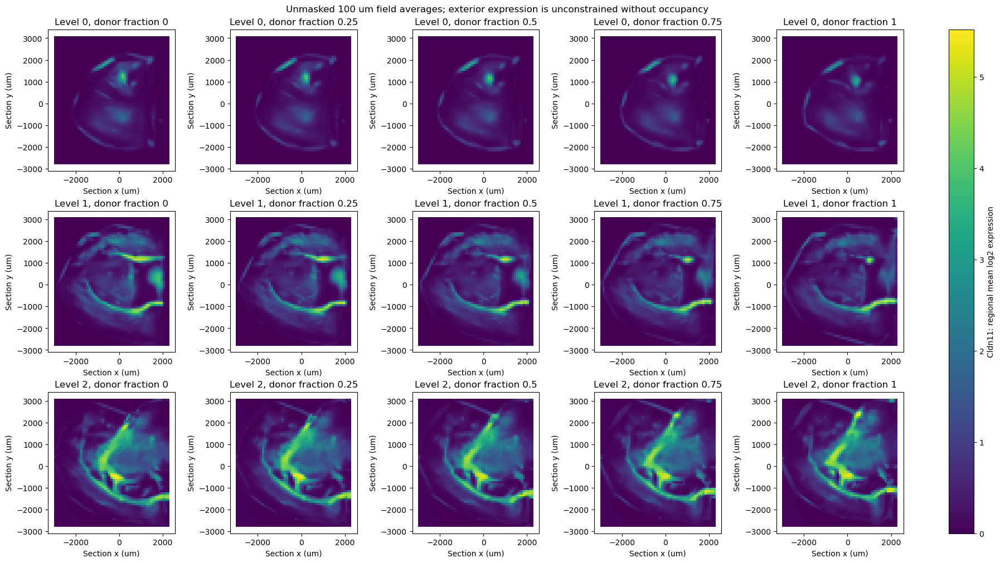

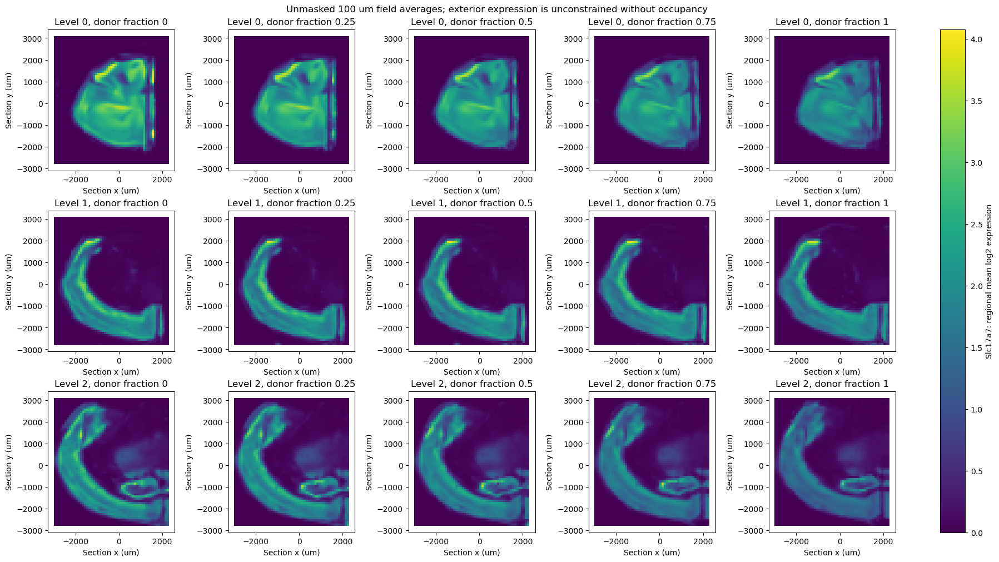

In [5]:
# Unmasked regional canvas: no endpoint support masks are used here.
# These are area-quadrature displays, distinct from measurement-weighted endpoint evaluation.
if reg_ready:
    alignment = pd.read_csv(reg_source/'alignment.csv')
    units_um = float(alignment.common_scale.iloc[0])*1000.
    if not np.allclose(alignment.common_scale, alignment.common_scale.iloc[0]):
        raise ValueError('Expected one isotropic coordinate scale')
    step = REG_REFERENCE_WIDTH/units_um
    all_xy = np.concatenate([r['xy'] for r in reg_records])
    lo = np.floor(all_xy.min(0)/step).astype(int)
    hi = np.ceil(all_xy.max(0)/step).astype(int)
    xx, yy = np.meshgrid(np.arange(lo[0], hi[0]), np.arange(lo[1], hi[1]))
    centers = (np.column_stack([xx.ravel(), yy.ravel()])+0.5)*step
    ox, oy = np.meshgrid((np.arange(4)+0.5)/4-0.5, (np.arange(4)+0.5)/4-0.5)
    offsets = np.column_stack([ox.ravel(), oy.ravel()])*step
    queries = (centers[:, None]+offsets[None]).reshape(-1, 2).astype(np.float32)
    region_canvas = dict(centers_um=centers*units_um)
    reg_renders = {}
    for level in range(len(reg_settings['pairs'])):
        for alpha in REG_ALPHAS:
            values = predict_field(reg_model, queries, (level, alpha),
                batch_size=REG_CFG['render_batch_size']).reshape(len(centers), 16, -1).mean(1)
            reg_renders[level, alpha] = values
            field = export_field(reg_model, (level, alpha))
            np.savez_compressed(REG_OUTPUT/f'field_level{level}_alpha{alpha:.2f}.npz',
                **field, gene_ids=reg_genes, gene_symbols=reg_symbols,
                kernel_sharpness=reg_settings['kernel_sharpness'])
            np.savez_compressed(REG_OUTPUT/f'regions_level{level}_alpha{alpha:.2f}.npz',
                expression=values, centers_um=centers*units_um, gene_ids=reg_genes,
                width_um=REG_REFERENCE_WIDTH, quadrature_points=16)
    for gene in REG_MAP_GENES:
        j = reg_marker_indices[gene]
        vmax = max(float(v[:, j].max()) for v in reg_renders.values()) or 1.
        fig, axes = plt.subplots(len(reg_settings['pairs']), len(REG_ALPHAS),
            figsize=(18, 10), squeeze=False, constrained_layout=True)
        for level, row in enumerate(axes):
            for ax, alpha in zip(row, REG_ALPHAS):
                artist = draw_regional_map(ax, region_canvas, REG_REFERENCE_WIDTH,
                    reg_renders[level, alpha][:, j], vmin=0, vmax=vmax)
                ax.set_title(f'Level {level}, donor fraction {alpha:.2g}')
        fig.colorbar(artist, ax=axes.ravel().tolist(), label=f'{gene}: regional mean log2 expression')
        fig.suptitle('Unmasked 100 um field averages; exterior expression is unconstrained without occupancy')
        fig.savefig(REG_FIGURES/f'{gene}_regional_interpolation.png', dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)


### Interpretation and next stage

Prefer improved matched regional expression, marker boundaries and local contrast over prettier hard-label maps. The five R states summarize regional profiles and retain the regional diagnostic's reference and colors. Their fractions count eligible regions equally, not measurements or cell types. A spatial shuffle can preserve fractions and Frechet distance while destroying anatomy; use the paired metrics and marker-edge CSV alongside them. Real-real donor comparisons provide context, not biological confidence intervals from two donors.

Compare all scales and sections, including the coverage table: the five-measurement minimum can exclude many sparse 50 um squares, so fine-scale scores are conditional on denser eligible regions. Increasing cosine while flattening marker contrast is not an unqualified improvement. There is no validation-based selection here: all endpoints are training reconstructions and the final configured step is saved. The archived point-objective baseline is never overwritten. An optional point loss is explicit and defaults to zero.

Occupancy remains secondary. Enable it only after the regional checkpoint is complete. It warm-starts from that checkpoint, preserves this regional expression objective, and adds occupancy and center-consistency terms. Its residual geometry can move, unlike this initial controlled regional fit. Its before/after regional tables and maps assess whether those additions damage expression fidelity. No predicted mask gates either regional expression loss or evaluation.

The historical point-level experiments below are retained for provenance, not the primary regional narrative. Their saved outputs describe older objectives.


## Historical point-level experiment (disabled by default)

## Settings and provenance

All eligible measurements and all shared genes are retained. Downloads use the existing ABC cache under SPATSPLAT_DATA_DIR (or SPATSPLAT_ABC_ATLAS_DIR).

Published log2 expression is passed through unchanged. Totals are sums of log2 expression, not molecule burden. No batch correction or absent-gene padding is applied.

Both decoder variants use 100 balanced epochs. Every section contributes the same number of full minibatches per epoch; complete shuffled passes guarantee that every measurement is visited, and smaller sections are oversampled. This is more training than the original 10,000-step pilot. Training always runs; checkpoints are never silently loaded.

Initial log scale -4.5, scale bounds [-8, -2], sharpness 0.5, loss weights, and support settings match the ordinary reconstruction defaults in normalized coordinates. The cohort retains its common isotropic coordinate scale and rigid alignment; it does not share the independent notebook's per-section normalization or optimizer parameterization. Consequently this is a curriculum/setting match, not an exact replication of independent-field training.

New configuration and source hashes give this run separate output directories. Prior results remain on disk.

In [6]:
if RUN_EXPRESSION_EXPERIMENT:
    SETTINGS = dict(
        pairs=[['Zhuang-ABCA-1.041', 'Zhuang-ABCA-2.019'],
               ['Zhuang-ABCA-1.059', 'Zhuang-ABCA-2.028'],
               ['Zhuang-ABCA-1.079', 'Zhuang-ABCA-2.036']],
        manifest=DEFAULT_MANIFEST, expression_kind='log2', max_measurements=None,
        seed=3107, num_splats=512, latent_dim=32, ae_hidden=128, ae_epochs=150,
        generator_width=128, slot_dim=32, embedding_dim=8,
        steps=10000, epochs=100, batch_size=512, lr=1e-3, kernel_sharpness=0.5,
        cosine_weight=1., total_weight=0.1, mae_weight=1., mae_refine_fraction=0.25,
        init_log_scale=-4.5, min_scale=math.exp(-8), max_scale=math.exp(-2),
        support_weight=0.001, support_radius=0.02, off_tissue_weight=0.0005,
        epoch_checkpoint_every=10, decoder_variants=["frozen", "trainable"],
        checkpoint_every=500, max_rotation_degrees=30, num_programs=8, grid_size=160)
    ALLOW_DOWNLOAD = True
    RUN_LEGACY_DIAGNOSTICS = False
    RUN_LOSS_BALANCE = False
    DONORS = ['Zhuang-ABCA-1', 'Zhuang-ABCA-2']
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    seed = SETTINGS['seed']
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    print(f'Device: {DEVICE}')
    atlas = ZhuangMouseBrainAtlas(manifest=SETTINGS['manifest'], allow_download=ALLOW_DOWNLOAD)
    display(atlas.download_plan(expression_kind=SETTINGS['expression_kind']))
    sources = ['paper/cohort_field_synthesis.py', 'paper/conditional_field.py',
               'paper/data_loaders/zhuang_mouse_brain.py', 'spatsplat/autoencoder.py',
               'spatsplat/models.py']
    provenance = dict(settings=SETTINGS, atlas_manifest_sha256=atlas.manifest_sha256,
        sources={p: hashlib.sha256((PROJECT_ROOT / p).read_bytes()).hexdigest() for p in sources},
        versions=dict(torch=torch.__version__, numpy=np.__version__))
    RUN_ID = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:12]
    OUTPUT_DIR = data_directory() / 'processed' / 'zhuang_conditional_synthesis' / RUN_ID
    FIGURE_DIR = PROJECT_ROOT / 'figures' / 'zhuang_conditional_synthesis' / RUN_ID
    CHECKPOINT_DIR = PROJECT_ROOT / 'notebooks' / 'checkpoints' / 'zhuang_conditional_synthesis' / RUN_ID
    for directory in [OUTPUT_DIR, FIGURE_DIR, CHECKPOINT_DIR]:
        directory.mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / 'manifest.json').write_text(json.dumps(provenance, indent=2))
    def save_figure(fig, name):
        fig.savefig(FIGURE_DIR / f'{name}.png', dpi=180, bbox_inches='tight', facecolor='white')
    print(f'Outputs: {OUTPUT_DIR}\nFigures: {FIGURE_DIR}\nCheckpoints: {CHECKPOINT_DIR}')


Device: cuda


,donor,directory,file_name,stage,size_gib,cached,path
0,Zhuang-ABCA-1,Zhuang-ABCA-1,gene,gene panel,7.886e-05,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...
1,Zhuang-ABCA-1,Zhuang-ABCA-1,cell_metadata,metadata,0.6156,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...
2,Zhuang-ABCA-1,Zhuang-ABCA-1,Zhuang-ABCA-1/log2,expression,1.982,True,/data/spatsplat/data/raw/abc_atlas/expression_...
3,Zhuang-ABCA-1,Zhuang-ABCA-1-CCF,ccf_coordinates,CCF,0.2056,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...
4,Zhuang-ABCA-2,Zhuang-ABCA-2,gene,gene panel,7.886e-05,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...
5,Zhuang-ABCA-2,Zhuang-ABCA-2,cell_metadata,metadata,0.2659,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...
6,Zhuang-ABCA-2,Zhuang-ABCA-2,Zhuang-ABCA-2/log2,expression,0.8116,True,/data/spatsplat/data/raw/abc_atlas/expression_...
7,Zhuang-ABCA-2,Zhuang-ABCA-2-CCF,ccf_coordinates,CCF,0.08297,True,/data/spatsplat/data/raw/abc_atlas/metadata/Zh...


Outputs: /data/spatsplat/data/processed/zhuang_conditional_synthesis/6fa020a20e5d
Figures: /home/javeda/Documents/Research/spatsplat/figures/zhuang_conditional_synthesis/6fa020a20e5d
Checkpoints: /home/javeda/Documents/Research/spatsplat/notebooks/checkpoints/zhuang_conditional_synthesis/6fa020a20e5d


## Load six complete sections

Observation IDs are joined to expression rows by the loader. max_measurements=None removes the former 6,000-measurement cap; QC still removes invalid profiles or coordinates. The common gene panel is retained. These are two biological donors, not six independent animals.

In [7]:
if RUN_EXPRESSION_EXPERIMENT:
    gene_tables = {d: atlas.genes(d) for d in DONORS}
    gene_ids = np.array(sorted(set.intersection(*(set(g.index) for g in gene_tables.values()))))
    gene_symbols = gene_tables[DONORS[0]].loc[gene_ids, 'gene_symbol'].to_numpy(dtype=str)
    if not np.array_equal(gene_symbols, gene_tables[DONORS[1]].loc[gene_ids, 'gene_symbol'].to_numpy(dtype=str)):
        raise ValueError('Review gene symbol discrepancies before fitting')
    records = []
    for donor_index, donor in enumerate(DONORS):
        extracted = atlas.load_sections(donor, [p[donor_index] for p in SETTINGS['pairs']],
            gene_ids=gene_ids, expression_kind=SETTINGS['expression_kind'],
            max_measurements=SETTINGS['max_measurements'], seed=seed)
        for level, pair in enumerate(SETTINGS['pairs']):
            record = dict(extracted[pair[donor_index]], level=level, donor_index=donor_index)
            records.append(record)
            np.savez_compressed(OUTPUT_DIR / f"{record['section']}.npz", **record)
    display(pd.DataFrame([dict(section=r['section'], level=r['level'], donor=r['donor'],
        measurements=len(r['expression']), genes=len(gene_ids), z=r['z'],
        mean_expression=float(r['expression'].mean()),
        median_total_expression=float(np.median(r['expression'].sum(1)))) for r in records]))


,section,level,donor,measurements,genes,z,mean_expression,median_total_expression
0,Zhuang-ABCA-1.041,0,Zhuang-ABCA-1,12473,1122,3.295,0.1249,144
1,Zhuang-ABCA-1.059,1,Zhuang-ABCA-1,23905,1122,5.114,0.119,135.8
2,Zhuang-ABCA-1.079,2,Zhuang-ABCA-1,31982,1122,6.659,0.1153,132.2
3,Zhuang-ABCA-2.019,0,Zhuang-ABCA-2,13825,1122,3.291,0.1227,142
4,Zhuang-ABCA-2.028,1,Zhuang-ABCA-2,30303,1122,5.164,0.124,142.1
5,Zhuang-ABCA-2.036,2,Zhuang-ABCA-2,33378,1122,6.623,0.119,136.1


## Geometry-only alignment

Each section is median-centered. A single isotropic scale is shared by all sections; donor B is rotated by at most 30 degrees to minimize symmetric nearest-neighbor geometry error against donor A at the same level. This is deliberately restricted rigid alignment, not full anatomical registration. It cannot correct tears, different cuts, or local distortions.

Inspect the overlay before interpreting interpolation. No genes are used to choose alignment. Relative sizes and internal gaps remain visible.

,section,level,donor_index,center_x,center_y,common_scale,rotation_degrees,pair_geometry_error_before,pair_geometry_error_after
0,Zhuang-ABCA-1.041,0,0,4.323,3.839,5.783,0,0.0001061,0.0001038
1,Zhuang-ABCA-2.019,0,1,4.066,4.104,5.783,2.231,0.0001061,0.0001038
2,Zhuang-ABCA-1.059,1,0,3.874,3.936,5.783,0,0.0001106,0.00011
3,Zhuang-ABCA-2.028,1,1,3.852,3.699,5.783,-0.8537,0.0001106,0.00011
4,Zhuang-ABCA-1.079,2,0,3.562,3.598,5.783,0,0.0001171,0.000116
5,Zhuang-ABCA-2.036,2,1,3.794,3.659,5.783,-0.7255,0.0001171,0.000116


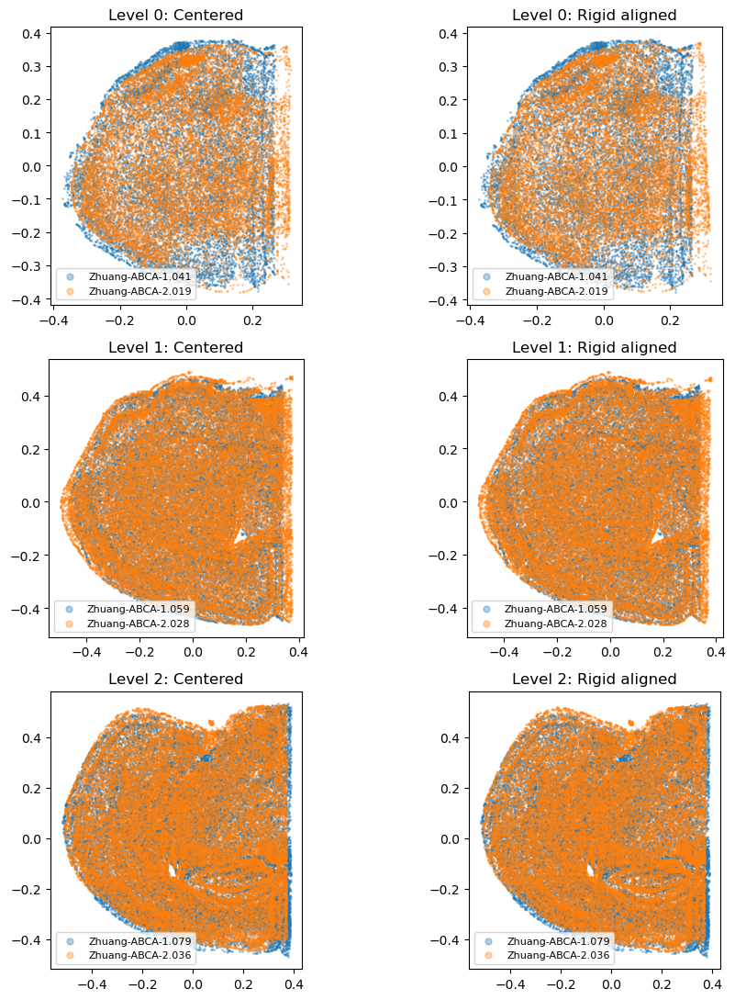

In [8]:
if RUN_EXPRESSION_EXPERIMENT:
    records, alignment_audit = align_sections(records, max_rotation_degrees=SETTINGS['max_rotation_degrees'])
    pd.DataFrame(alignment_audit).to_csv(OUTPUT_DIR / 'alignment.csv', index=False)
    display(pd.DataFrame(alignment_audit))
    fig, axes = plt.subplots(len(SETTINGS['pairs']), 2, figsize=(10, 11), squeeze=False)
    for level in range(len(SETTINGS['pairs'])):
        for r in [r for r in records if r['level'] == level]:
            before = (r['xy_raw']-np.median(r['xy_raw'], axis=0))/alignment_audit[0]['common_scale']
            for col, points in enumerate([before, r['xy']]):
                axes[level, col].scatter(*points.T, s=1, alpha=0.35, label=r['section'])
                axes[level, col].set(aspect='equal', title=f'Level {level}: '+['Centered', 'Rigid aligned'][col])
        for ax in axes[level]:
            ax.legend(markerscale=5, fontsize=8)
    fig.tight_layout()
    save_figure(fig, 'alignment')
    plt.show()


## Shared autoencoder

All sections contribute to one expression representation. A random 10% of measurements per section monitors AE reconstruction only; these are not held-out tissues and are subsequently used for field fitting. Both generator variants start from this exact AE. Decoder training, when enabled, modifies a private copy and never changes this AE.

The per-section table reports expression-to-expression recovery, not spatial prediction.

In [9]:
if RUN_EXPRESSION_EXPERIMENT:
    all_expression = np.concatenate([r['expression'] for r in records])
    profiles = torch.from_numpy(all_expression/all_expression.sum(1, keepdims=True))
    rng = np.random.default_rng(seed)
    train_idx, monitor_idx, offset = [], [], 0
    for r in records:
        order = rng.permutation(len(r['expression']))+offset
        n_monitor = max(1, len(order)//10)
        monitor_idx.extend(order[:n_monitor])
        train_idx.extend(order[n_monitor:])
        offset += len(order)
    ae = GeneProfileAutoencoder(len(gene_ids), SETTINGS['ae_hidden'], SETTINGS['latent_dim']).to(DEVICE)
    def ae_progress(epoch, loss, metrics):
        if (epoch+1) % 25 == 0 or epoch == 0:
            print(f"AE epoch {epoch+1}: monitor cosine={metrics['cosine']:.4g}, MAE={metrics['mae']:.4g}", flush=True)
    ae_history = train_profile_autoencoder(ae, profiles, torch.tensor(train_idx), torch.tensor(monitor_idx),
        epochs=SETTINGS['ae_epochs'], batch_size=SETTINGS['batch_size'], on_epoch_end=ae_progress)
    ae.eval().requires_grad_(False)
    torch.save(dict(state_dict=ae.state_dict(), provenance=provenance, gene_ids=gene_ids.tolist()),
               CHECKPOINT_DIR / 'autoencoder.pt')
    pd.DataFrame(ae_history).to_csv(OUTPUT_DIR / 'ae_history.csv', index=False)
    ae_rows = []
    for r in records:
        p = torch.from_numpy(r['expression']/r['expression'].sum(1, keepdims=True))
        ae_rows.append(dict(section=r['section'], **evaluate_profile_autoencoder(ae, p, torch.arange(len(p)))))
    display(pd.DataFrame(ae_rows))
    pd.DataFrame(ae_rows).to_csv(OUTPUT_DIR / 'ae_reconstruction.csv', index=False)


AE epoch 1: monitor cosine=0.5988, MAE=0.001181
AE epoch 25: monitor cosine=0.7609, MAE=0.0009076
AE epoch 50: monitor cosine=0.7731, MAE=0.0008804
AE epoch 75: monitor cosine=0.7798, MAE=0.0008634
AE epoch 100: monitor cosine=0.7842, MAE=0.0008524
AE epoch 125: monitor cosine=0.7863, MAE=0.0008477
AE epoch 150: monitor cosine=0.7865, MAE=0.0008439


,section,loss,mae,cosine,n
0,Zhuang-ABCA-1.041,5.498,0.0008253,0.798,12473
1,Zhuang-ABCA-2.019,5.389,0.0008154,0.7998,13825
2,Zhuang-ABCA-1.059,5.427,0.0008531,0.7843,23905
3,Zhuang-ABCA-2.028,5.481,0.0008183,0.8011,30303
4,Zhuang-ABCA-1.079,5.375,0.0008866,0.7644,31982
5,Zhuang-ABCA-2.036,5.395,0.0008075,0.8071,33378


## Matched frozen/trainable decoder runs

Both runs start with identical emitted splats, shared decoder weights, and conditioning network weights. Only decoder trainability differs. Complete balanced epochs use the same deterministic minibatch sequence.

The first 75% of epochs optimize cosine dissimilarity plus log-total-expression error, with center support and off-support expression penalties. The final 25% add unnormalized MAE. At that transition a frozen copy of the geometric mapping preserves positions, scales, and rotations for all conditions, including interpolated donor embeddings. Latents, amplitudes, and the trainable decoder can continue learning.

A simple detach of geometry outputs would not suffice: updates to the shared network could still move them. The frozen mapping is included in checkpoints and parameter counts. This generator does not learn opacity; that is another difference from independently optimized ordinary fields.

All endpoint metrics are in-sample final-epoch scores. Their purpose is to compare these two runs, not to claim superiority over held-out reconstruction scores.

frozen: trainable parameters=44,110
Epoch 1 [composition]: cosine=0.5218, MAE=0.1727
Epoch 10 [composition]: cosine=0.5621, MAE=0.1668
Epoch 20 [composition]: cosine=0.5695, MAE=0.1647
Epoch 30 [composition]: cosine=0.5728, MAE=0.1638
Epoch 40 [composition]: cosine=0.5736, MAE=0.1633
Epoch 50 [composition]: cosine=0.575, MAE=0.1631
Epoch 60 [composition]: cosine=0.575, MAE=0.1634
Epoch 70 [composition]: cosine=0.576, MAE=0.1629
Epoch 80 [mae_refine]: cosine=0.5758, MAE=0.151
Epoch 90 [mae_refine]: cosine=0.5764, MAE=0.1514
Epoch 100 [mae_refine]: cosine=0.577, MAE=0.1505
trainable: trainable parameters=209,713
Epoch 1 [composition]: cosine=0.5305, MAE=0.1717
Epoch 10 [composition]: cosine=0.5659, MAE=0.1663
Epoch 20 [composition]: cosine=0.5707, MAE=0.1641
Epoch 30 [composition]: cosine=0.5755, MAE=0.1632
Epoch 40 [composition]: cosine=0.577, MAE=0.1621
Epoch 50 [composition]: cosine=0.5779, MAE=0.1617
Epoch 60 [composition]: cosine=0.5787, MAE=0.162
Epoch 70 [composition]: cosine=0.57

,variant,section,expression_mae,profile_cosine,log_total_mae,mean_total_ratio
0,frozen,Zhuang-ABCA-1.041,0.1545,0.5797,0.161,0.9239
1,frozen,Zhuang-ABCA-2.019,0.1511,0.5791,0.1579,0.9234
2,frozen,Zhuang-ABCA-1.059,0.1507,0.5695,0.1767,0.9054
3,frozen,Zhuang-ABCA-2.028,0.1537,0.5844,0.1571,0.924
4,frozen,Zhuang-ABCA-1.079,0.1489,0.5516,0.2022,0.8935
5,frozen,Zhuang-ABCA-2.036,0.1441,0.5974,0.1672,0.9097
6,trainable,Zhuang-ABCA-1.041,0.1485,0.5765,0.1609,0.9233
7,trainable,Zhuang-ABCA-2.019,0.1453,0.576,0.1611,0.916
8,trainable,Zhuang-ABCA-1.059,0.1446,0.57,0.1753,0.907
9,trainable,Zhuang-ABCA-2.028,0.1473,0.5838,0.1593,0.924


,expression_mae,profile_cosine,log_total_mae,mean_total_ratio
variant,,,,
frozen,0.1505,0.577,0.1704,0.9133
trainable,0.1442,0.5769,0.17,0.9127


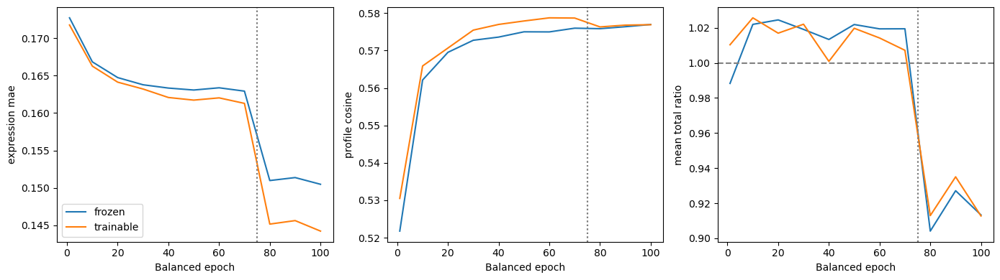

In [10]:
if RUN_EXPRESSION_EXPERIMENT:
    initialization = initialize_from_observations(
        np.concatenate([r['xy'] for r in records]), all_expression, ae,
        num_splats=SETTINGS['num_splats'], seed=seed)
    torch.manual_seed(seed)
    template = CohortSplatGenerator(initialization, ae.decoder, num_levels=len(SETTINGS['pairs']),
        width=SETTINGS['generator_width'], slot_dim=SETTINGS['slot_dim'],
        embedding_dim=SETTINGS['embedding_dim'], kernel_sharpness=SETTINGS['kernel_sharpness'],
        init_log_scale=SETTINGS['init_log_scale'], min_scale=SETTINGS['min_scale'],
        max_scale=SETTINGS['max_scale']).to(DEVICE)
    models, histories, endpoint_rows = {}, {}, []
    initial_state = {k: v.detach().clone() for k, v in template.state_dict().items()}
    for variant in SETTINGS['decoder_variants']:
        current = copy.deepcopy(template)
        current.renderer.field.decoder.requires_grad_(variant == 'trainable')
        assert all(torch.equal(value, current.state_dict()[key]) for key, value in initial_state.items())
        variant_dir = OUTPUT_DIR / variant
        variant_checkpoints = CHECKPOINT_DIR / variant
        variant_dir.mkdir(parents=True, exist_ok=True)
        variant_checkpoints.mkdir(parents=True, exist_ok=True)
        print(f"{variant}: trainable parameters={sum(p.numel() for p in current.parameters() if p.requires_grad):,}")
        def checkpoint(current, trace):
            torch.save(dict(state_dict=current.state_dict(), initialization=initialization,
                provenance=provenance, decoder_variant=variant, geometry_frozen=current.geometry_snapshot is not None,
                history=trace, gene_ids=gene_ids.tolist()), variant_checkpoints / 'generator_latest.pt')
            pd.DataFrame(trace).to_csv(variant_dir / 'field_history.csv', index=False)
        trace = fit_cohort_curriculum(current, records, seed=seed, on_checkpoint=checkpoint,
            checkpoint_every=SETTINGS['epoch_checkpoint_every'],
            **{k: SETTINGS[k] for k in ['epochs', 'batch_size', 'lr', 'cosine_weight', 'total_weight',
                'mae_weight', 'mae_refine_fraction', 'support_weight', 'support_radius', 'off_tissue_weight']})
        models[variant] = current.cpu()
        histories[variant] = trace
        predictions = {}
        current.to(DEVICE)
        for r in records:
            pred = predict_field(current, r['xy'], r['condition'])
            predictions[r['section']] = pred
            endpoint_rows.append(dict(variant=variant, section=r['section'],
                **field_metrics(pred, r['expression']),
                mean_total_ratio=float(pred.sum(1).mean()/r['expression'].sum(1).mean())))
        np.savez_compressed(variant_dir / 'endpoint_predictions.npz', **predictions)
        current.cpu()
        del predictions
    del template, initial_state
    metrics = pd.DataFrame(endpoint_rows)
    display(metrics)
    display(metrics.groupby('variant')[['expression_mae', 'profile_cosine', 'log_total_mae', 'mean_total_ratio']].mean())
    metrics.to_csv(OUTPUT_DIR / 'reconstruction_metrics.csv', index=False)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for variant, trace in histories.items():
        means = pd.DataFrame(trace).groupby('epoch').mean(numeric_only=True)
        for ax, metric in zip(axes, ['expression_mae', 'profile_cosine', 'mean_total_ratio']):
            ax.plot(means.index, means[metric], label=variant)
            ax.set(xlabel='Balanced epoch', ylabel=metric.replace('_', ' '))
            ax.axvline(round((1-SETTINGS['mae_refine_fraction'])*SETTINGS['epochs']), color='gray', linestyle=':')
    axes[0].legend()
    axes[2].axhline(1, color='gray', linestyle='--')
    fig.tight_layout()
    save_figure(fig, 'decoder_comparison_training')
    plt.show()
    # Legacy diagnostics below use a named reference, not whichever loop ran last.
    model = models['frozen'].to(DEVICE)


## Donor-embedding interpolation

Columns show donor A observations, its reconstruction, three synthetic intermediates, donor B reconstruction, and donor B observations. Each gene uses one fixed color scale across all levels and columns.

Intermediate fields are rendered on the **union of endpoint observation supports** (nearest-observation radius), not a learned synthetic tissue mask. This fixed display support avoids inventing an interpolated outline; it must not be interpreted as generated anatomy. Exported field parameters do not include that mask. A separate unmasked center plot below exposes geometry outside observed support.

These are nonlinear generator outputs at interpolated embeddings, not pixelwise blends. The diagnostic table compares them with endpoint-field blends; differences alone do not establish biological realism.

Both variants are plotted and exported separately with identical gene scales. Use the same variant when comparing endpoints and intermediates. The program color key is shared between variants.

,level,alpha,difference_from_endpoint_blend
0,0,0,0
1,0,0.25,0.01717
2,0,0.5,0.02466
3,0,0.75,0.01896
4,0,1,0
5,1,0,0
6,1,0.25,0.009936
7,1,0.5,0.01426
8,1,0.75,0.01128
9,1,1,0


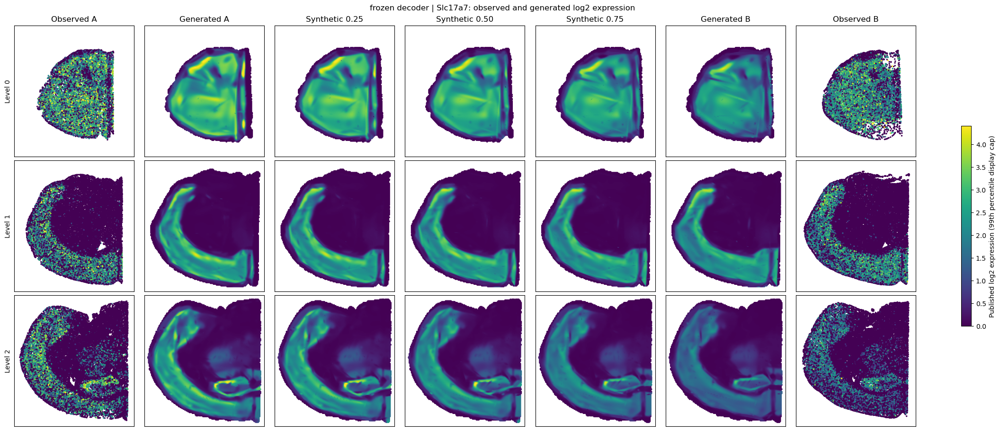

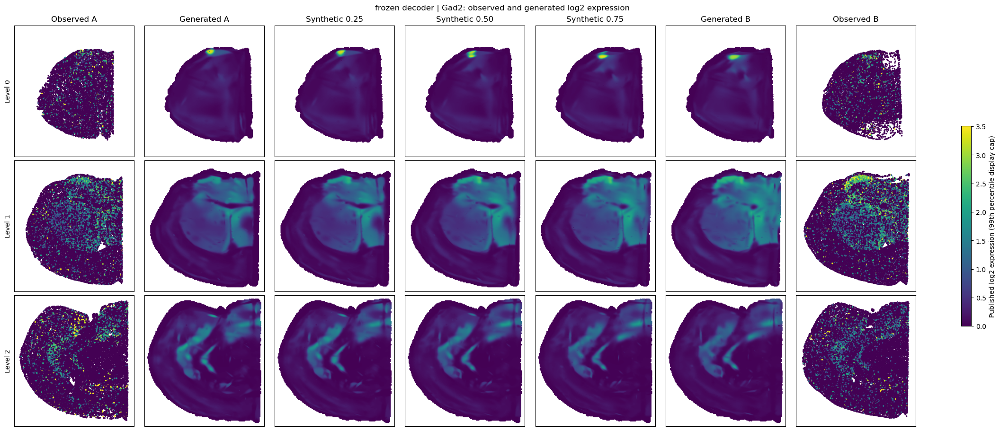

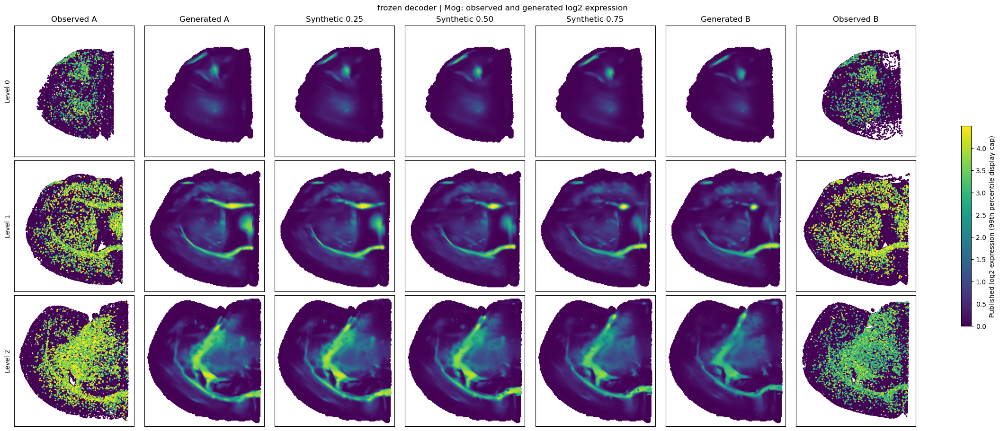

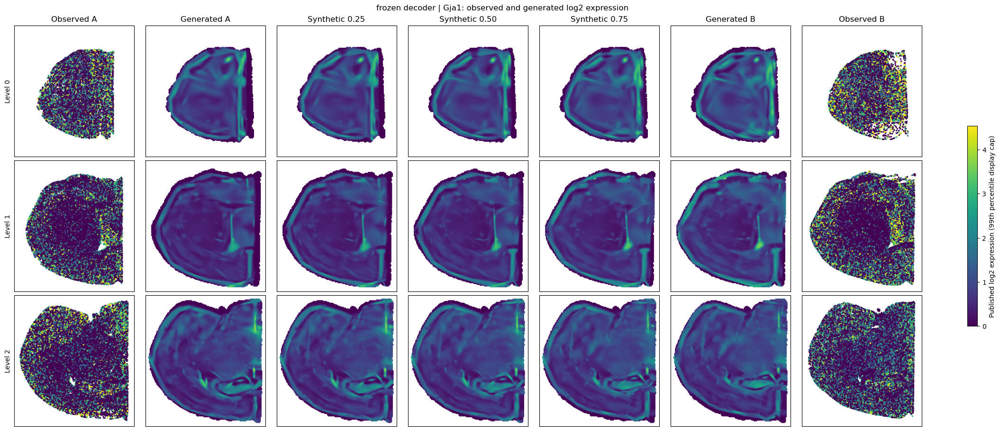

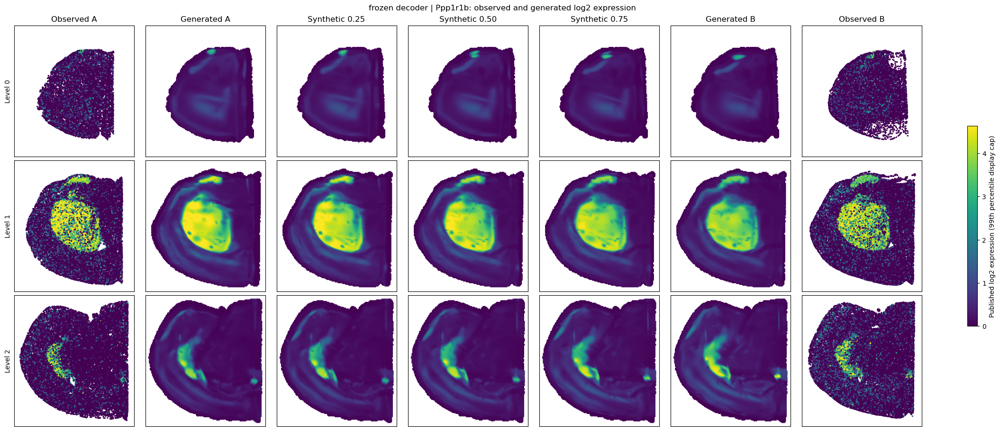

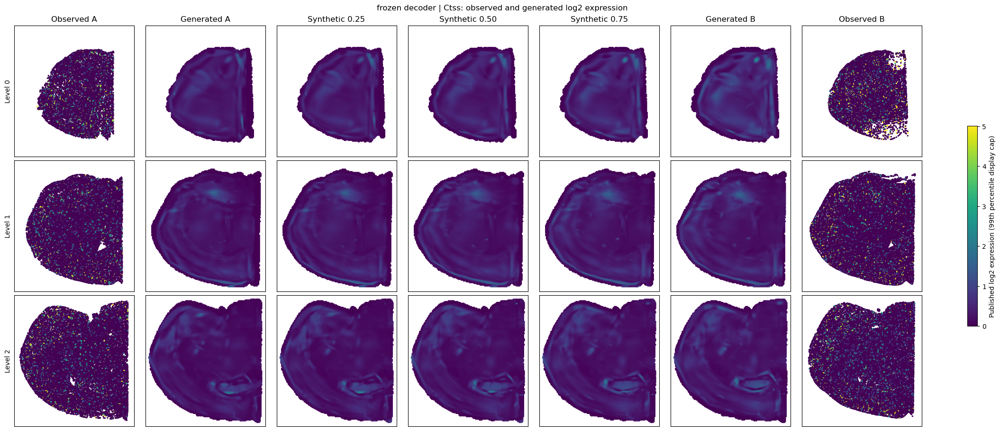

,level,alpha,difference_from_endpoint_blend
0,0,0,0
1,0,0.25,0.01813
2,0,0.5,0.02675
3,0,0.75,0.02069
4,0,1,0
5,1,0,0
6,1,0.25,0.01075
7,1,0.5,0.01458
8,1,0.75,0.01096
9,1,1,0


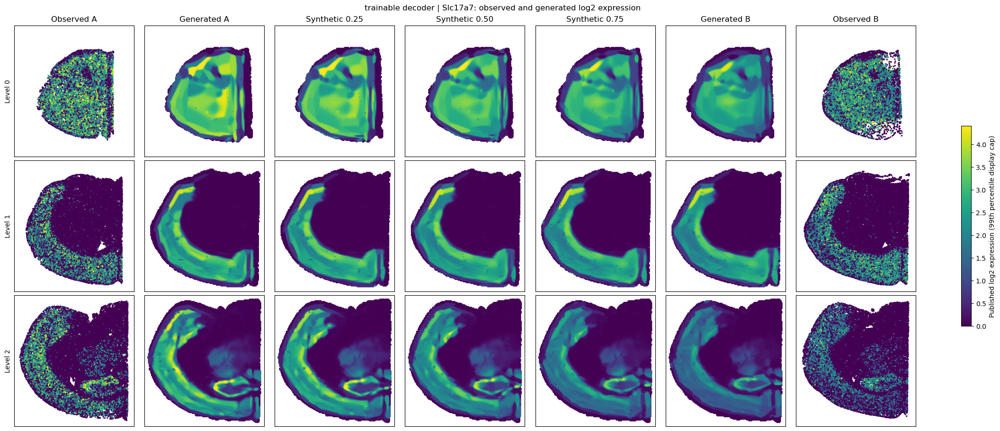

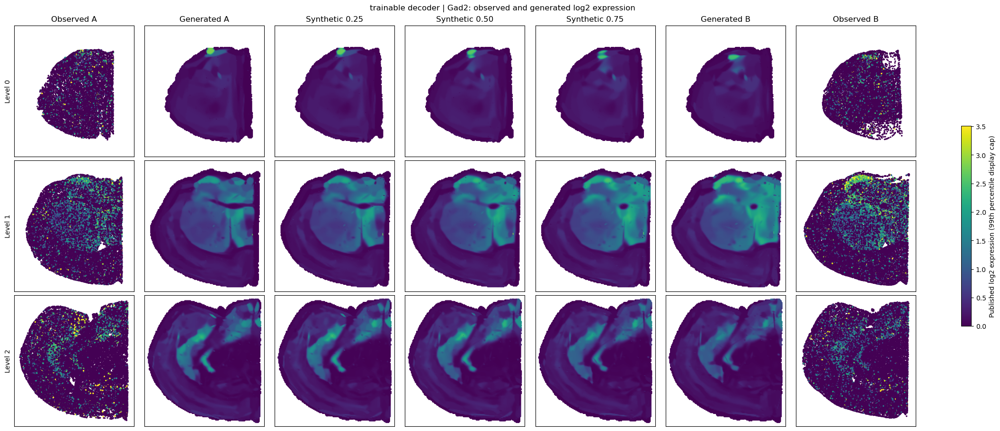

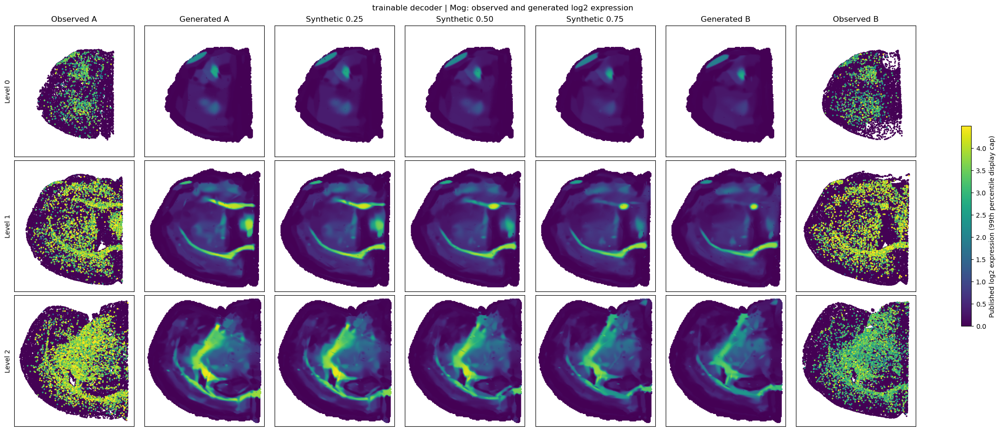

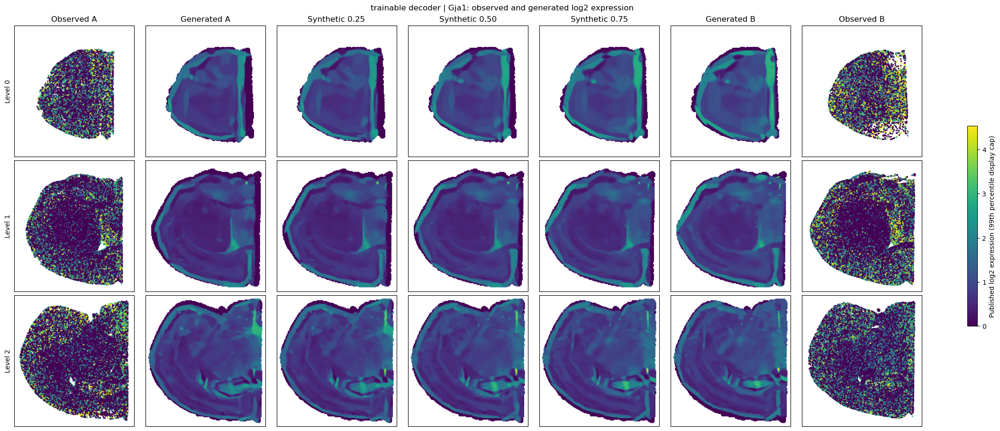

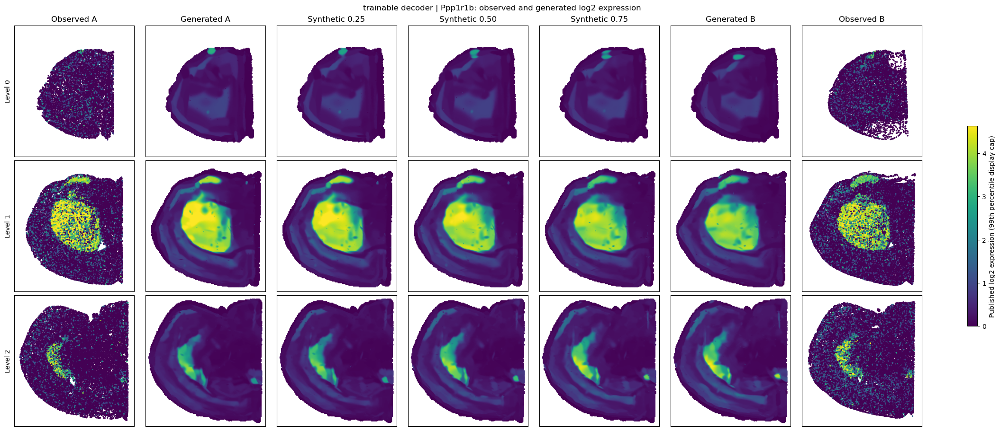

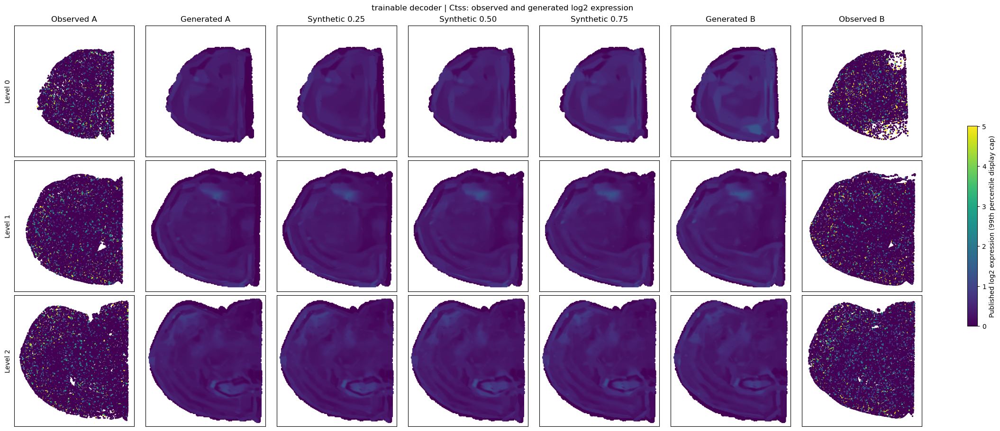

In [11]:
if RUN_EXPRESSION_EXPERIMENT:
    renders_by_variant = {}
    def save_variant_figure(fig, name):
        save_figure(fig, f'{variant}_{name}')
    for variant in SETTINGS['decoder_variants']:
        model = models[variant].to(DEVICE)
        ALPHAS = [0., 0.25, 0.5, 0.75, 1.]
        PLOT_GENES = ['Slc17a7', 'Gad2', 'Mog', 'Gja1', 'Ppp1r1b', 'Ctss']
        gene_lookup = {symbol: i for i, symbol in enumerate(gene_symbols)}
        missing = [g for g in PLOT_GENES if g not in gene_lookup]
        if missing:
            print(f'Absent requested genes: {missing}')
        PLOT_GENES = [g for g in PLOT_GENES if g in gene_lookup]
        if not PLOT_GENES:
            PLOT_GENES = gene_symbols[np.argsort(all_expression.mean(0))[-3:]].tolist()
        all_xy = np.concatenate([r['xy'] for r in records])
        lower, upper = all_xy.min(0)-0.05, all_xy.max(0)+0.05
        gx, gy = np.meshgrid(np.linspace(lower[0], upper[0], SETTINGS['grid_size']),
                             np.linspace(lower[1], upper[1], SETTINGS['grid_size']))
        grid = np.column_stack([gx.ravel(), gy.ravel()]).astype(np.float32)
        renders, supports, interpolation_rows = {}, {}, []
        for level in range(len(SETTINGS['pairs'])):
            pair = [r for r in records if r['level'] == level]
            supports[level] = cKDTree(np.concatenate([r['xy'] for r in pair])).query(grid)[0] <= SETTINGS['support_radius']
            renders[level] = [predict_field(model, grid, (level, alpha)) for alpha in ALPHAS]
            for alpha, prediction in zip(ALPHAS, renders[level]):
                exported = export_field(model, (level, alpha))
                np.savez_compressed(OUTPUT_DIR / variant / f'field_level{level}_alpha{alpha:.2f}.npz',
                                    **exported, gene_ids=gene_ids, gene_symbols=gene_symbols)
                blend = (1-alpha)*renders[level][0]+alpha*renders[level][-1]
                interpolation_rows.append(dict(level=level, alpha=alpha,
                    difference_from_endpoint_blend=float(np.abs(prediction[supports[level]]-blend[supports[level]]).mean())))
        display(pd.DataFrame(interpolation_rows))
        pd.DataFrame(interpolation_rows).to_csv(OUTPUT_DIR / variant / 'interpolation.csv', index=False)
        titles = ['Observed A', 'Generated A', 'Synthetic 0.25', 'Synthetic 0.50',
                  'Synthetic 0.75', 'Generated B', 'Observed B']
        for gene in PLOT_GENES:
            g = gene_lookup[gene]
            vmax = max(float(np.quantile(all_expression[:, g], 0.99)), 1e-6)
            fig, axes = plt.subplots(len(SETTINGS['pairs']), 7, figsize=(21, 9), squeeze=False,
                                     constrained_layout=True)
            for level in range(len(SETTINGS['pairs'])):
                pair = sorted([r for r in records if r['level'] == level], key=lambda r: r['donor_index'])
                for col, r in [(0, pair[0]), (6, pair[1])]:
                    artist = axes[level, col].scatter(*r['xy'].T, c=r['expression'][:, g], s=2,
                                                     cmap='viridis', vmin=0, vmax=vmax, rasterized=True)
                for col, values in enumerate(renders[level], start=1):
                    mask = supports[level]
                    axes[level, col].scatter(*grid[mask].T, c=values[mask, g], s=3,
                                             cmap='viridis', vmin=0, vmax=vmax, rasterized=True)
                for col, ax in enumerate(axes[level]):
                    ax.set(aspect='equal', xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]),
                           title=titles[col] if level == 0 else '', xticks=[], yticks=[])
                axes[level, 0].set_ylabel(f'Level {level}')
            fig.suptitle(f'{variant} decoder | {gene}: observed and generated log2 expression')
            fig.colorbar(artist, ax=axes, shrink=0.5, label='Published log2 expression (99th percentile display cap)')
            save_variant_figure(fig, f'interpolation_{gene}')
            plt.show()
    
        renders_by_variant[variant] = renders
        model.cpu()


## Shared expression-program colors

KMeans prototypes are fitted once to normalized observed profiles pooled from all six sections. Every observed or rendered profile is assigned to its nearest prototype using the same labels and colors. These are descriptive expression clusters, not annotated cell types. The marker table helps interpret the arbitrary program numbers. Clustering is for visualization only and does not constrain generation.

,program,color,highest_profile_genes
0,P0,#1f77b4,"Slc38a1, Slc32a1, Sulf2, Ntrk3, Gad2"
1,P1,#ff7f0e,"Zic1, Igf2, Rgs5, Mfge8, Tns1"
2,P2,#2ca02c,"Slc17a7, Sv2b, Ptk2b, Mef2c, Gda"
3,P3,#9467bd,"Cldn5, Slco1c1, Fn1, Adgrf5, S1pr1"
4,P4,#8c564b,"Cldn11, Mog, Sox10, Gprc5b, Sec14l5"
5,P5,#7f7f7f,"Gja1, Mfge8, Gpr37l1, Acsbg1, S1pr1"
6,P6,#bcbd22,"Ppp1r1b, Penk, Scn4b, Ptk2b, Gpr88"
7,P7,#17becf,"Ctss, Sall1, Mafb, Maf, Fyb"


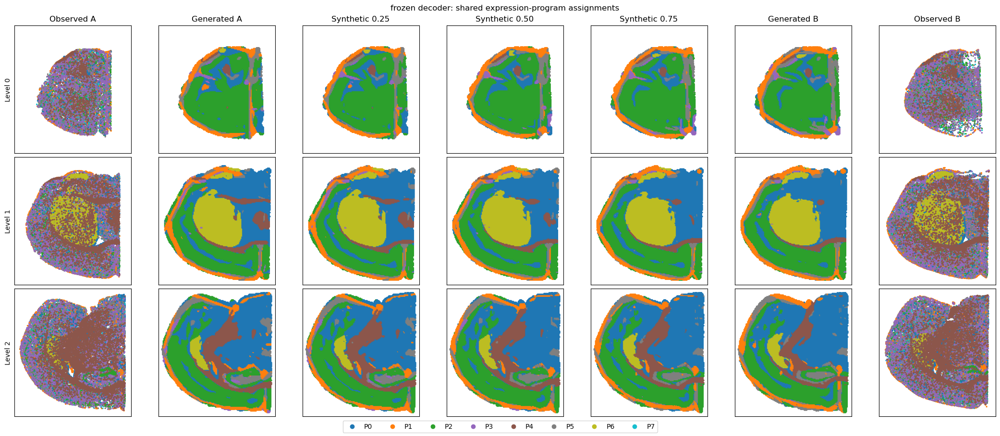

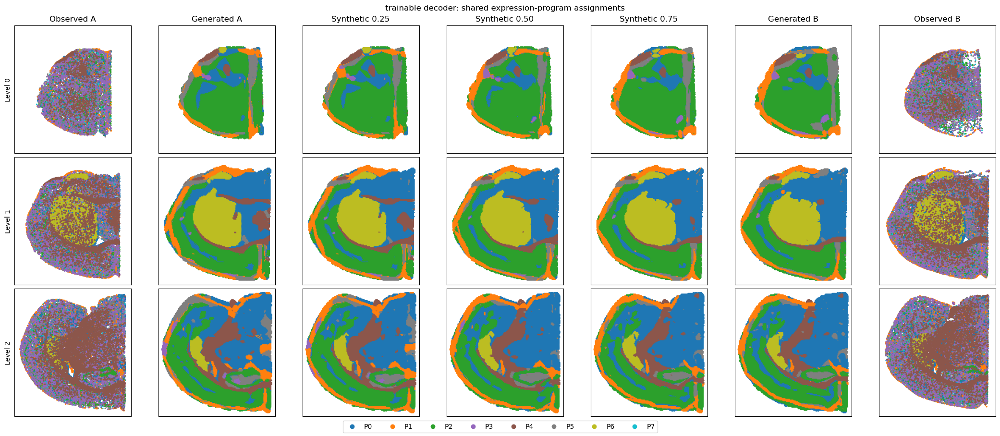

In [12]:
if RUN_EXPRESSION_EXPERIMENT:
    programs = KMeans(n_clusters=SETTINGS['num_programs'], n_init=10, random_state=seed).fit(profiles.numpy())
    program_colors = plt.get_cmap('tab10', SETTINGS['num_programs'])
    program_table = pd.DataFrame([dict(program=f'P{k}', color=plt.matplotlib.colors.to_hex(program_colors(k)),
        highest_profile_genes=', '.join(gene_symbols[np.argsort(center)[-5:][::-1]]))
        for k, center in enumerate(programs.cluster_centers_)])
    display(program_table)
    program_table.to_csv(OUTPUT_DIR / 'program_legend.csv', index=False)
    np.savez_compressed(OUTPUT_DIR / 'program_prototypes.npz', centers=programs.cluster_centers_, gene_ids=gene_ids)
    for variant in SETTINGS['decoder_variants']:
        renders = renders_by_variant[variant]
        fig, axes = plt.subplots(len(SETTINGS['pairs']), 7, figsize=(21, 9), squeeze=False, constrained_layout=True)
        for level in range(len(SETTINGS['pairs'])):
            pair = sorted([r for r in records if r['level'] == level], key=lambda r: r['donor_index'])
            panels = [(pair[0]['xy'], pair[0]['expression'])]
            panels += [(grid[supports[level]], v[supports[level]]) for v in renders[level]]
            panels += [(pair[1]['xy'], pair[1]['expression'])]
            for col, (xy, values) in enumerate(panels):
                labels = programs.predict(values/values.sum(1, keepdims=True).clip(1e-8))
                axes[level, col].scatter(*xy.T, c=labels, s=2, cmap=program_colors,
                                        vmin=-0.5, vmax=SETTINGS['num_programs']-0.5, rasterized=True)
                axes[level, col].set(aspect='equal', xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]),
                                    title=titles[col] if level == 0 else '', xticks=[], yticks=[])
            axes[level, 0].set_ylabel(f'Level {level}')
        from matplotlib.lines import Line2D
        fig.legend(handles=[Line2D([], [], color=program_colors(k), marker='o', linestyle='', label=f'P{k}')
                            for k in range(SETTINGS['num_programs'])], loc='outside lower center',
                   ncol=SETTINGS['num_programs'])
        fig.suptitle(f'{variant} decoder: shared expression-program assignments')
        save_variant_figure(fig, 'program_interpolation')
        plt.show()
    

## Unmasked splat geometry

Ellipses show one geometric scale, not hard biological boundaries; kernel sharpness also affects responsibilities. Gray points show both endpoint supports at that level. All emitted centers are shown, including those away from observations. The support distance diagnostic uses the union for intermediates and the corresponding donor for endpoints.

Visually coherent interpolation is a feasibility result. Failure to reconstruct endpoints means interpolation is not yet interpretable. Plausible intermediates do not establish donor-distribution learning, new-animal validity, or complete anatomy generation.

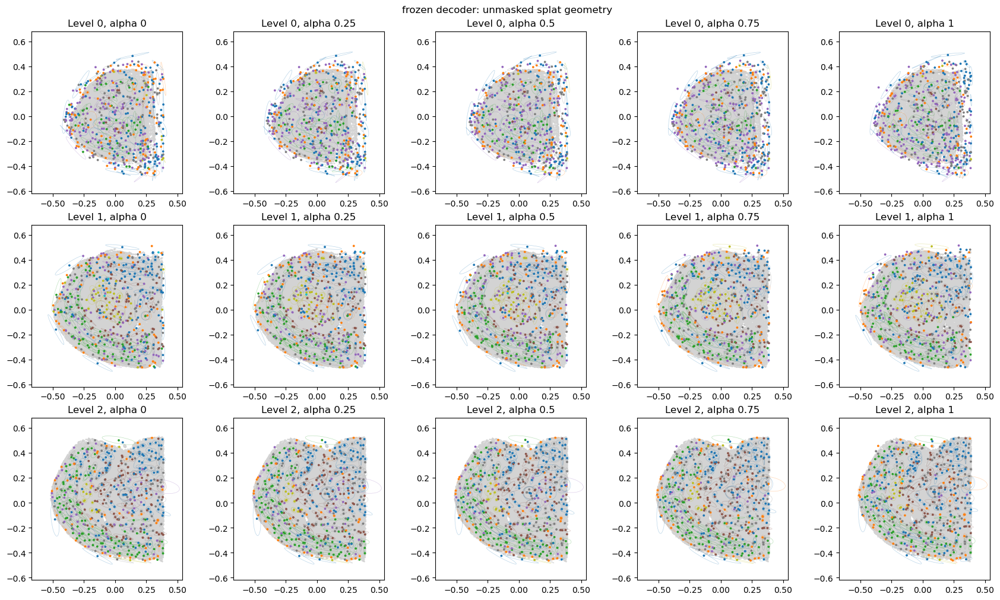

,level,alpha,fraction_centers_outside_support,median_support_distance
0,0,0,0.332,0.00469
1,0,0.25,0.2559,0.003115
2,0,0.5,0.2617,0.002954
3,0,0.75,0.25,0.002855
4,0,1,0.3066,0.004984
5,1,0,0.08203,0.00282
6,1,0.25,0.02148,0.001872
7,1,0.5,0.02734,0.001784
8,1,0.75,0.02734,0.001823
9,1,1,0.04102,0.002438


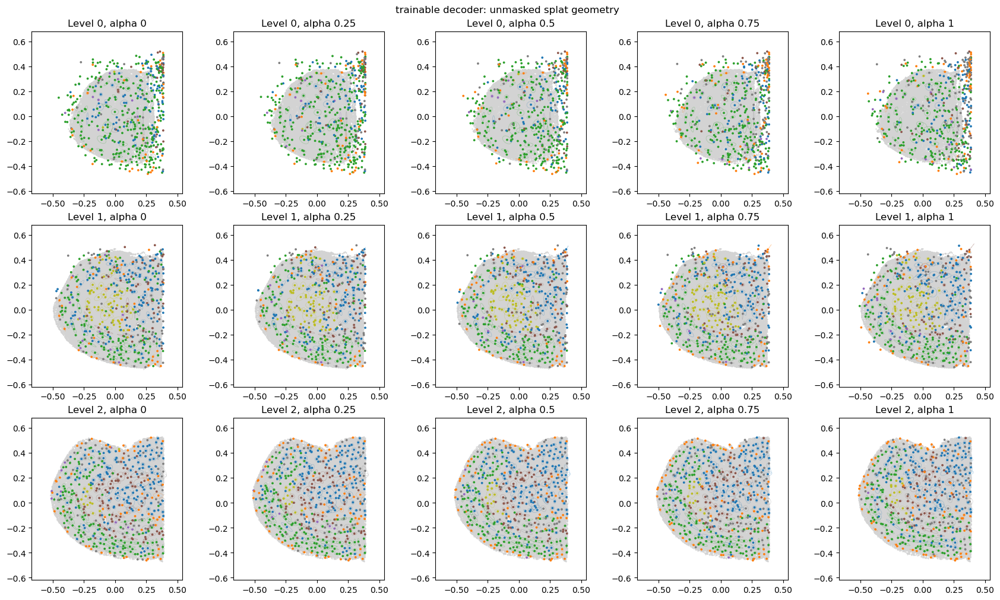

,level,alpha,fraction_centers_outside_support,median_support_distance
0,0,0,0.5078,0.02203
1,0,0.25,0.4102,0.005099
2,0,0.5,0.4121,0.004789
3,0,0.75,0.4121,0.005331
4,0,1,0.4355,0.01237
5,1,0,0.1094,0.002731
6,1,0.25,0.02539,0.001919
7,1,0.5,0.03125,0.001838
8,1,0.75,0.03516,0.001712
9,1,1,0.04297,0.002313


In [13]:
if RUN_EXPRESSION_EXPERIMENT:
    for variant in SETTINGS['decoder_variants']:
        model = models[variant].to(DEVICE)
        from matplotlib.patches import Ellipse
        fig, axes = plt.subplots(len(SETTINGS['pairs']), len(ALPHAS), figsize=(17, 10), squeeze=False,
                                 constrained_layout=True)
        geometry_rows = []
        for level in range(len(SETTINGS['pairs'])):
            pair = sorted([r for r in records if r['level'] == level], key=lambda r: r['donor_index'])
            union = np.concatenate([r['xy'] for r in pair])
            for col, alpha in enumerate(ALPHAS):
                field = export_field(model, (level, alpha))
                labels = programs.predict(field['profiles'])
                ax = axes[level, col]
                ax.scatter(*union.T, s=0.3, color='lightgray')
                for mean, scale, angle, label in zip(field['means'], np.exp(field['log_scales']),
                                                    field['rotation'].ravel(), labels):
                    ax.add_patch(Ellipse(mean, 2*scale[0], 2*scale[1], angle=np.rad2deg(angle),
                                        facecolor='none', edgecolor=program_colors(label), alpha=0.3, lw=0.5))
                ax.scatter(*field['means'].T, s=3, c=labels, cmap=program_colors,
                           vmin=-0.5, vmax=SETTINGS['num_programs']-0.5)
                ax.set(aspect='equal', xlim=(lower[0]-0.1, upper[0]+0.1),
                       ylim=(lower[1]-0.1, upper[1]+0.1), title=f'Level {level}, alpha {alpha:.2g}')
                support = pair[int(alpha)]['xy'] if alpha in [0., 1.] else union
                distance = cKDTree(support).query(field['means'])[0]
                geometry_rows.append(dict(level=level, alpha=alpha,
                    fraction_centers_outside_support=float(np.mean(distance > SETTINGS['support_radius'])),
                    median_support_distance=float(np.median(distance))))
        fig.suptitle(f'{variant} decoder: unmasked splat geometry')
        save_variant_figure(fig, 'unmasked_splat_geometry')
        plt.show()
        display(pd.DataFrame(geometry_rows))
        pd.DataFrame(geometry_rows).to_csv(OUTPUT_DIR / variant / 'geometry.csv', index=False)
    
        model.cpu()
    model = models['frozen'].to(DEVICE)


## Optional legacy single-section diagnostic

Disabled by default (RUN_LEGACY_DIAGNOSTICS=False). This retains the earlier simultaneous normalized-MAE objective and step-based budget for historical investigation; it is **not** a matched control for the new curriculum. Its step-exposure estimate describes the historical random-step sampler, not the new balanced epochs. The frozen-decoder variant is the reference model. Enable deliberately, not as part of the main comparison.

## Diagnostic: independently optimized single-section splats

Run this section after the existing AE and generator training cells; it does not retrain or modify them. Default: the first section, chosen by order rather than performance.

Two independent fields use the **same frozen decoder, splat count, kernel, geometry bounds, support radius, loss weights, and original cohort MAE normalization**. One starts from the original pooled initialization; the other starts from the trained generator's output. Only the splat parameters are optimized, without the conditional network. There are no held-out claims.

The first budget matches the exact number of updates allocated to this section by the cohort's seeded sampler. The final budget gives the independent field as many updates as the entire cohort received. The warm-start control additionally inherits prior cohort training, so it is not compute-matched.

A substantial improvement would show recoverable fit lost to conditioning/parameterization or optimization. Similar results would not prove an intrinsic spatial ceiling; the AE, loss, initialization, and finite training remain shared limitations.

In [14]:
if RUN_EXPRESSION_EXPERIMENT:
    if RUN_LEGACY_DIAGNOSTICS:
        # Refresh helpers added after this kernel trained the generator; preserve model and ae.
        import importlib
        import paper.cohort_field_synthesis as cohort_synthesis
        cohort_synthesis = importlib.reload(cohort_synthesis)
        IndependentSectionField = cohort_synthesis.IndependentSectionField
        fit_cohort = cohort_synthesis.fit_cohort
        DIAGNOSTIC_SECTION = SETTINGS['pairs'][0][0]
        diagnostic_record = next(r for r in records if r['section'] == DIAGNOSTIC_SECTION)
        diagnostic_index = next(i for i, r in enumerate(records) if r['section'] == DIAGNOSTIC_SECTION)
        # Replay both draws made in each original training step to count actual section exposure.
        exposure_rng = np.random.default_rng(SETTINGS['seed'])
        section_updates = 0
        for _ in range(SETTINGS['steps']):
            selected = int(exposure_rng.integers(len(records)))
            exposure_rng.integers(len(records[selected]['xy']), size=SETTINGS['batch_size'])
            section_updates += int(selected == diagnostic_index)
        diagnostic_scale = max(float(np.mean([r['expression'].mean() for r in records])), 1e-6)
        diagnostic_dir = OUTPUT_DIR / 'independent_section' / DIAGNOSTIC_SECTION
        diagnostic_figures = FIGURE_DIR / 'independent_section'
        diagnostic_checkpoints = CHECKPOINT_DIR / 'independent_section'
        for directory in [diagnostic_dir, diagnostic_figures, diagnostic_checkpoints]:
            directory.mkdir(parents=True, exist_ok=True)
        diagnostic_manifest = dict(section=DIAGNOSTIC_SECTION, original_cohort_updates=section_updates,
            independent_total_updates=SETTINGS['steps'], expression_scale=diagnostic_scale,
            settings=SETTINGS, source_sha256=hashlib.sha256(
                (PROJECT_ROOT / 'paper/cohort_field_synthesis.py').read_bytes()).hexdigest())
        (diagnostic_dir / 'manifest.json').write_text(json.dumps(diagnostic_manifest, indent=2))
        print(f'Section: {DIAGNOSTIC_SECTION}; original section updates: {section_updates}; '
              f'independent final updates: {SETTINGS["steps"]}')
        diagnostic_predictions = {'Conditional generator': predict_field(
            model, diagnostic_record['xy'], diagnostic_record['condition'])}
        diagnostic_rows = []
        def record_diagnostic(label, prediction, updates):
            diagnostic_rows.append(dict(model=label, updates=updates,
                **field_metrics(prediction, diagnostic_record['expression'])))
        record_diagnostic('Conditional generator', diagnostic_predictions['Conditional generator'], section_updates)
        # The zero predictor contextualizes MAE only; zero-vector cosine is not meaningful.
        zero_mae = float(diagnostic_record['expression'].mean())
        print(f'Zero-prediction MAE: {zero_mae:.4g}')
    
        for warm_start, name in [(False, 'Independent original init'), (True, 'Independent warm start')]:
            independent = IndependentSectionField(model, diagnostic_record['condition'], warm_start=warm_start).to(DEVICE)
            before = predict_field(independent, diagnostic_record['xy'], diagnostic_record['condition'])
            record_diagnostic(name+' before fitting', before, 0)
            if warm_start:
                np.testing.assert_allclose(before, diagnostic_predictions['Conditional generator'], rtol=1e-4, atol=1e-5)
            recorded_exposure = False
            def save_independent(current, trace):
                global recorded_exposure
                step = trace[-1]['step']
                if step == section_updates and not recorded_exposure:
                    prediction = predict_field(current, diagnostic_record['xy'], diagnostic_record['condition'])
                    record_diagnostic(name+' section-exposure budget', prediction, step)
                    recorded_exposure = True
                torch.save(dict(state_dict=current.state_dict(), manifest=diagnostic_manifest,
                                warm_start=warm_start, history=trace),
                           diagnostic_checkpoints / f'{DIAGNOSTIC_SECTION}_{warm_start}.pt')
            # Check every step only when needed would be expensive; use a divisor that
            # hits the exposure budget exactly, then also evaluate the final step.
            interval = max(1, section_updates)
            trace = fit_cohort(independent, [diagnostic_record], steps=SETTINGS['steps'],
                checkpoint_every=interval, seed=SETTINGS['seed'], expression_scale=diagnostic_scale,
                on_checkpoint=save_independent,
                **{k: SETTINGS[k] for k in ['batch_size', 'lr', 'cosine_weight', 'total_weight',
                                           'support_weight', 'support_radius']})
            prediction = predict_field(independent, diagnostic_record['xy'], diagnostic_record['condition'])
            diagnostic_predictions[name] = prediction
            record_diagnostic(name+' final', prediction, SETTINGS['steps'])
            pd.DataFrame(trace).to_csv(diagnostic_dir / f'history_{warm_start}.csv', index=False)
            np.savez_compressed(diagnostic_dir / f'field_{warm_start}.npz',
                                **export_field(independent, diagnostic_record['condition']), gene_ids=gene_ids)
            del independent
    
        diagnostic_table = pd.DataFrame(diagnostic_rows)
        diagnostic_table['cosine_gain_over_conditional'] = diagnostic_table.profile_cosine-diagnostic_rows[0]['profile_cosine']
        display(diagnostic_table)
        diagnostic_table.to_csv(diagnostic_dir / 'comparison.csv', index=False)
        np.savez_compressed(diagnostic_dir / 'predictions.npz',
            observed=diagnostic_record['expression'], xy=diagnostic_record['xy'],
            **{name.replace(' ', '_'): value for name, value in diagnostic_predictions.items()})
    
    else:
        print('Legacy independent diagnostic skipped.')


Legacy independent diagnostic skipped.


### Matched-location comparison

Every panel uses the same observed coordinates, point size, and gene-specific color scale. This avoids comparing scattered observations to a dense smoothed grid. Available markers are displayed across several programs; no gene is selected based on its reconstruction score. These are in-sample reconstructions, not synthetic interpolation panels.

In [15]:
if RUN_EXPRESSION_EXPERIMENT:
    if RUN_LEGACY_DIAGNOSTICS:
        diagnostic_genes = [g for g in ['Slc17a7', 'Gad2', 'Mog', 'Gja1', 'Ppp1r1b', 'Ctss']
                            if g in set(gene_symbols)]
        if not diagnostic_genes:
            diagnostic_genes = gene_symbols[:3].tolist()
        panels = {'Observed': diagnostic_record['expression'], **diagnostic_predictions}
        fig, axes = plt.subplots(len(diagnostic_genes), len(panels),
            figsize=(14, 3*len(diagnostic_genes)), squeeze=False, constrained_layout=True)
        xy = diagnostic_record['xy']
        for row, gene in enumerate(diagnostic_genes):
            index = int(np.flatnonzero(gene_symbols == gene)[0])
            vmax = max(float(np.quantile(diagnostic_record['expression'][:, index], 0.99)), 1e-6)
            for col, (label, values) in enumerate(panels.items()):
                artist = axes[row, col].scatter(*xy.T, c=values[:, index], s=2, cmap='viridis', vmin=0, vmax=vmax)
                axes[row, col].set(aspect='equal', title=label if row == 0 else '', xticks=[], yticks=[])
            axes[row, 0].set_ylabel(gene)
            fig.colorbar(artist, ax=axes[row].tolist(), shrink=0.7, label='Log2 expression')
        fig.suptitle(f'{DIAGNOSTIC_SECTION}: matched-location reconstruction')
        fig.savefig(diagnostic_figures / f'{DIAGNOSTIC_SECTION}.png', dpi=180, bbox_inches='tight')
        plt.show()
    
    else:
        print('Legacy independent diagnostic skipped.')


Legacy independent diagnostic skipped.


## Optional legacy loss-weight sweep

Disabled by default (RUN_LOSS_BALANCE=False). This is a separate simultaneous normalized-MAE loss sweep, not the reconstruction curriculum. It does not alter either conditional generator.

## Loss-balance experiment: separate composition and total-expression effects

This four-setting factorial experiment fits independent splats on the same diagnostic section. All runs start from the **same original pooled initialization**, not from the previous trained fields. Only cosine and total-expression weights change; normalized MAE has coefficient 1, and decoder, kernel, geometry bounds, support penalty, minibatch sequence, learning rate, and training steps remain fixed. The baseline is deliberately rerun.

Higher cosine tests profile agreement; higher total-expression weight tests expression suppression. Their combination tests the interaction. All metrics remain **in-sample** and final-step, not checkpoint-selected. This is one section and one seed, not a generalization comparison. A larger total alone cannot improve cosine by rescaling.

Success means a useful tradeoff: improved cosine and total-expression calibration without unacceptable MAE or leakage into measurements where a gene is zero. Total expression here sums published log2 values, not raw molecules.

In [16]:
if RUN_EXPRESSION_EXPERIMENT:
    if RUN_LOSS_BALANCE:
        import importlib
        import paper.cohort_field_synthesis as cohort_synthesis
        cohort_synthesis = importlib.reload(cohort_synthesis)
        IndependentSectionField = cohort_synthesis.IndependentSectionField
        fit_cohort = cohort_synthesis.fit_cohort
    
        LOSS_BALANCE_SECTION = SETTINGS['pairs'][0][0]
        LOSS_BALANCE_STEPS = SETTINGS['steps']
        LOSS_BALANCE_SEED = SETTINGS['seed']
        LOSS_BALANCE_CASES = [
            dict(name='Baseline', cosine_weight=SETTINGS['cosine_weight'], total_weight=SETTINGS['total_weight']),
            dict(name='Higher cosine', cosine_weight=4*SETTINGS['cosine_weight'], total_weight=SETTINGS['total_weight']),
            dict(name='Higher total', cosine_weight=SETTINGS['cosine_weight'], total_weight=10*SETTINGS['total_weight']),
            dict(name='Higher both', cosine_weight=4*SETTINGS['cosine_weight'], total_weight=10*SETTINGS['total_weight']),
        ]
        if SETTINGS['cosine_weight'] <= 0 or SETTINGS['total_weight'] <= 0:
            raise ValueError('Set explicit positive weights for the loss-balance comparison')
        loss_record = next(r for r in records if r['section'] == LOSS_BALANCE_SECTION)
        loss_scale = max(float(np.mean([r['expression'].mean() for r in records])), 1e-6)
        loss_manifest = dict(section=LOSS_BALANCE_SECTION, cases=LOSS_BALANCE_CASES,
            steps=LOSS_BALANCE_STEPS, seed=LOSS_BALANCE_SEED, expression_scale=loss_scale,
            initialization='original pooled initialization', settings=SETTINGS,
            source_sha256=hashlib.sha256((PROJECT_ROOT / 'paper/cohort_field_synthesis.py').read_bytes()).hexdigest())
        loss_id = hashlib.sha256(json.dumps(loss_manifest, sort_keys=True).encode()).hexdigest()[:12]
        loss_dir = OUTPUT_DIR / 'loss_balance' / loss_id
        loss_figures = FIGURE_DIR / 'loss_balance' / loss_id
        loss_checkpoints = CHECKPOINT_DIR / 'loss_balance' / loss_id
        for directory in [loss_dir, loss_figures, loss_checkpoints]:
            directory.mkdir(parents=True, exist_ok=True)
        (loss_dir / 'manifest.json').write_text(json.dumps(loss_manifest, indent=2))
        display(pd.DataFrame(LOSS_BALANCE_CASES))
        print(f'{len(LOSS_BALANCE_CASES)} fresh fits, {LOSS_BALANCE_STEPS} updates each; outputs: {loss_dir}')
    
    else:
        print('Legacy loss-balance sweep skipped.')


Legacy loss-balance sweep skipped.


In [17]:
if RUN_EXPRESSION_EXPERIMENT:
    if RUN_LOSS_BALANCE:
        def loss_balance_metrics(prediction, target):
            pred_total, true_total = prediction.sum(1), target.sum(1)
            return dict(**field_metrics(prediction, target),
                mean_total_ratio=float(pred_total.mean()/true_total.mean()),
                median_total_ratio=float(np.median(pred_total/true_total.clip(1e-8))),
                signed_log_total_error=float(np.mean(np.log1p(pred_total)-np.log1p(true_total))))
    
        loss_predictions, loss_rows, loss_histories, loss_gene_rows = {}, [], [], []
        loss_marker_genes = [g for g in ['Slc17a7', 'Gad2', 'Mog', 'Gja1', 'Ppp1r1b', 'Ctss']
                             if g in set(gene_symbols)]
        if not loss_marker_genes:
            loss_marker_genes = gene_symbols[:3].tolist()
        conditional_prediction = predict_field(model, loss_record['xy'], loss_record['condition'])
        loss_rows.append(dict(model='Conditional reference', **loss_balance_metrics(
            conditional_prediction, loss_record['expression'])))
        initial_snapshot = None
        for case in LOSS_BALANCE_CASES:
            name = case['name']
            print(f"Fitting {name}: cosine={case['cosine_weight']:.4g}, total={case['total_weight']:.4g}", flush=True)
            field = IndependentSectionField(model, loss_record['condition'], warm_start=False).to(DEVICE)
            snapshot = {k: v.detach().cpu().clone() for k, v in field.state_dict().items()}
            if initial_snapshot is None:
                initial_snapshot = snapshot
            else:
                assert all(torch.equal(v, initial_snapshot[k]) for k, v in snapshot.items()), 'Initialization changed'
            def loss_checkpoint(current, trace):
                prediction = predict_field(current, loss_record['xy'], loss_record['condition'])
                stats = loss_balance_metrics(prediction, loss_record['expression'])
                loss_histories.append(dict(model=name, step=trace[-1]['step'], **stats))
                print(f"  total ratio={stats['mean_total_ratio']:.4g}, "
                      f"signed log-total error={stats['signed_log_total_error']:.4g}", flush=True)
                pd.DataFrame(loss_histories).to_csv(loss_dir / 'history.csv', index=False)
                torch.save(dict(state_dict=current.state_dict(), manifest=loss_manifest, case=case, history=trace),
                           loss_checkpoints / f"{name.replace(' ', '_')}.pt")
            fit_cohort(field, [loss_record], steps=LOSS_BALANCE_STEPS,
                checkpoint_every=SETTINGS['checkpoint_every'], seed=LOSS_BALANCE_SEED,
                expression_scale=loss_scale, on_checkpoint=loss_checkpoint,
                cosine_weight=case['cosine_weight'], total_weight=case['total_weight'],
                **{k: SETTINGS[k] for k in ['batch_size', 'lr', 'support_weight', 'support_radius']})
            prediction = predict_field(field, loss_record['xy'], loss_record['condition'])
            loss_predictions[name] = prediction
            loss_rows.append(dict(model=name, **loss_balance_metrics(prediction, loss_record['expression'])))
            for gene in loss_marker_genes:
                g = int(np.flatnonzero(gene_symbols == gene)[0])
                true, pred = loss_record['expression'][:, g], prediction[:, g]
                positive = true > 0
                correlation = (float(np.corrcoef(true, pred)[0, 1])
                               if np.std(true) > 0 and np.std(pred) > 0 else np.nan)
                loss_gene_rows.append(dict(model=name, gene=gene,
                    positive_measurements=int(positive.sum()), gene_correlation=correlation,
                    gene_mae=float(np.abs(pred-true).mean()),
                    positive_recovery_ratio=float(pred[positive].sum()/true[positive].sum()) if positive.any() else np.nan,
                    zero_measurement_mean_prediction=float(pred[~positive].mean()) if (~positive).any() else np.nan))
            np.savez_compressed(loss_dir / f"{name.replace(' ', '_')}_field.npz",
                                **export_field(field, loss_record['condition']), gene_ids=gene_ids)
            del field
        loss_table = pd.DataFrame(loss_rows)
        baseline = loss_table.loc[loss_table.model == 'Baseline'].iloc[0]
        loss_table['cosine_gain_over_baseline'] = loss_table.profile_cosine-baseline.profile_cosine
        loss_table['mae_change_from_baseline'] = loss_table.expression_mae-baseline.expression_mae
        display(loss_table)
        display(pd.DataFrame(loss_gene_rows))
        loss_table.to_csv(loss_dir / 'comparison.csv', index=False)
        pd.DataFrame(loss_gene_rows).to_csv(loss_dir / 'marker_recovery.csv', index=False)
        np.savez_compressed(loss_dir / 'predictions.npz', observed=loss_record['expression'],
            xy=loss_record['xy'], gene_ids=gene_ids, conditional_reference=conditional_prediction,
            **{name.replace(' ', '_'): value for name, value in loss_predictions.items()})
    
    else:
        print('Legacy loss-balance sweep skipped.')


Legacy loss-balance sweep skipped.


### Interpret the comparison

- **Higher total restores total expression but not cosine:** intensity suppression and profile mismatch are distinct problems.
- **Higher cosine improves profiles:** the previous loss balance was sacrificing composition.
- **Higher both helps:** both objectives needed more influence relative to MAE.
- **Little improvement across settings:** investigate shared decoder limitations, spatial resolution, and local profile heterogeneity before enlarging the conditional generator.

Watch MAE and zero-measurement predictions alongside positive recovery: simply increasing expression everywhere is not recovery of the correct profiles. Zeros here are observed values, not proof of biological absence. None of these settings is automatically selected or propagated back into the generator.

In [18]:
if RUN_EXPRESSION_EXPERIMENT:
    if RUN_LOSS_BALANCE:
        fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
        for name, trace in pd.DataFrame(loss_histories).groupby('model', sort=False):
            for ax, metric in zip(axes, ['profile_cosine', 'expression_mae', 'mean_total_ratio']):
                ax.plot(trace.step, trace[metric], label=name)
                ax.set(xlabel='Section-specific updates', ylabel=metric.replace('_', ' '))
        axes[2].axhline(1, color='black', linestyle=':', linewidth=1)
        axes[0].legend(fontsize=8)
        fig.savefig(loss_figures / 'training.png', dpi=180, bbox_inches='tight')
        plt.show()
    
        panels = {'Observed': loss_record['expression'], **loss_predictions}
        fig, axes = plt.subplots(len(loss_marker_genes), len(panels),
            figsize=(17, 3*len(loss_marker_genes)), squeeze=False, constrained_layout=True)
        for row, gene in enumerate(loss_marker_genes):
            index = int(np.flatnonzero(gene_symbols == gene)[0])
            vmax = max(float(np.quantile(loss_record['expression'][:, index], 0.99)), 1e-6)
            for col, (name, values) in enumerate(panels.items()):
                artist = axes[row, col].scatter(*loss_record['xy'].T, c=values[:, index], s=2,
                                                cmap='viridis', vmin=0, vmax=vmax)
                axes[row, col].set(aspect='equal', title=name if row == 0 else '', xticks=[], yticks=[])
            axes[row, 0].set_ylabel(gene)
            fig.colorbar(artist, ax=axes[row].tolist(), shrink=0.7, label='Log2 expression')
        fig.suptitle(f'{LOSS_BALANCE_SECTION}: loss balance, same measurement coordinates and color scales')
        fig.savefig(loss_figures / 'marker_comparison.png', dpi=180, bbox_inches='tight')
        plt.show()
    
    else:
        print('Legacy loss-balance sweep skipped.')


Legacy loss-balance sweep skipped.


## Fixed-program comparison: archived 6,000 versus full-section runs

This section can run independently after the import cell; it does not train any model or require live AE/generator objects. The two archived run IDs below are explicit so rerunning the main experiment cannot silently change the comparison.

Primary analysis: use the **old observed-profile prototypes and their original colors** for both runs. Sensitivity analysis: repeat with the new observed-profile prototypes. Program numbers/colors are comparable across models within a dictionary, not between dictionaries.

Each section is restricted to shared measurement IDs, in identical row order. Gene panels are reordered by identifiers, and shared expression targets and raw coordinates must agree. Old predictions are rendered from exported splat geometry, decoded profiles, and amplitudes using that run's own coordinate transform and sharpness; no retraining or checkpoint loading occurs. New predictions are taken from archived endpoint predictions.

This distinguishes dictionary changes from a genuine change in program preservation. It does **not** isolate subsampling: losses, training budget, AE, initialization scales, and other settings also changed.

In [19]:
if RUN_EXPRESSION_EXPERIMENT:
    from paper.program_run_comparison import compare_runs
    OLD_PROGRAM_RUN = 'e2264c442116'
    NEW_PROGRAM_RUN = '6fa020a20e5d'
    comparison_root = data_directory() / 'processed' / 'zhuang_conditional_synthesis'
    old_program_dir = comparison_root / OLD_PROGRAM_RUN
    new_program_dir = comparison_root / NEW_PROGRAM_RUN
    comparison_settings = dict(old_run=OLD_PROGRAM_RUN, new_run=NEW_PROGRAM_RUN,
        variants=['frozen', 'trainable'], dictionaries=['old', 'new'],
        source_sha256=hashlib.sha256((PROJECT_ROOT/'paper/program_run_comparison.py').read_bytes()).hexdigest())
    comparison_id = hashlib.sha256(json.dumps(comparison_settings, sort_keys=True).encode()).hexdigest()[:12]
    comparison_dir = data_directory() / 'processed' / 'zhuang_program_comparison' / comparison_id
    comparison_figures = PROJECT_ROOT / 'figures' / 'zhuang_program_comparison' / comparison_id
    for directory in [comparison_dir, comparison_figures]:
        directory.mkdir(parents=True, exist_ok=True)
    comparison = compare_runs(old_program_dir, new_program_dir)
    for name in ['fractions', 'summaries', 'confusions', 'audit']:
        comparison[name].to_csv(comparison_dir / f'{name}.csv', index=False)
    (comparison_dir / 'manifest.json').write_text(json.dumps(comparison_settings, indent=2))
    display(comparison['audit'])
    print('Primary dictionary: old prototypes. All models are evaluated on the same measurements.')
    for dictionary in ['old', 'new']:
        print(f'Fixed {dictionary} dictionary')
        frame = comparison['fractions'].query('dictionary == @dictionary')
        pooled = frame.groupby(['model', 'program'])[['count', 'n']].sum()
        pooled['fraction'] = pooled['count']/pooled['n']
        display(pooled.fraction.unstack('model'))
        # Equal-section averages; pooled fractions above are explicitly measurement-weighted.
        display(comparison['summaries'].query('dictionary == @dictionary').groupby('model')[
            ['assignment_agreement', 'program_total_variation', 'profile_cosine', 'expression_mae']].mean())
    print(f'Comparison outputs: {comparison_dir}')


,section,old_measurements,new_measurements,shared_measurements,old_unmatched
0,Zhuang-ABCA-1.041,6000,12473,6000,0
1,Zhuang-ABCA-2.019,6000,13825,6000,0
2,Zhuang-ABCA-1.059,6000,23905,6000,0
3,Zhuang-ABCA-2.028,6000,30303,6000,0
4,Zhuang-ABCA-1.079,6000,31982,6000,0
5,Zhuang-ABCA-2.036,6000,33378,6000,0


Primary dictionary: old prototypes. All models are evaluated on the same measurements.
Fixed old dictionary


model,New frozen,New trainable,Observed,Old 6000
program,,,,
P0,0.4146,0.4273,0.2349,0.4386
P1,0.09386,0.1016,0.1394,0.1561
P2,0.05064,0.04481,0.1461,0.2359
P3,0.00825,0.005389,0.1238,0.007389
P4,0.2743,0.2558,0.1699,0.03567
P5,0.1054,0.109,0.07008,0.1166
P6,0,0,0.05356,0
P7,0.053,0.05619,0.06225,0.00975


,assignment_agreement,program_total_variation,profile_cosine,expression_mae
model,,,,
New frozen,0.4903,0.3202,0.5763,0.1506
New trainable,0.485,0.3195,0.5764,0.1443
Old 6000,0.4611,0.3738,0.481,0.119


Fixed new dictionary


model,New frozen,New trainable,Observed,Old 6000
program,,,,
P0,0.2671,0.2461,0.1704,0.03369
P1,0.0515,0.05419,0.06158,0.009556
P2,0.4234,0.4373,0.2356,0.4416
P3,0.008861,0.005833,0.1241,0.008306
P4,0.09336,0.1009,0.1392,0.1553
P5,0.05147,0.04733,0.1469,0.2349
P6,0.1043,0.1083,0.06889,0.1166
P7,0,0,0.05339,0


,assignment_agreement,program_total_variation,profile_cosine,expression_mae
model,,,,
New frozen,0.4914,0.3215,0.5763,0.1506
New trainable,0.4856,0.322,0.5764,0.1443
Old 6000,0.4608,0.3751,0.481,0.119


Comparison outputs: /data/spatsplat/data/processed/zhuang_program_comparison/2cadecb4726b


### Same colors, same measurements

The bars compare program frequencies. The maps use identical coordinates and point sizes, including for generated profiles. Confusion matrices show where each observed program is reassigned; each row sums to one when that observed program is present.

A lower total-variation distance indicates better preservation of assignment proportions, while agreement measures correct assignments at individual locations. Similar proportions alone can conceal misplaced programs. Conversely, hard cluster labels can amplify shifts in mixed profiles; they are descriptive expression-program assignments, not validated cell-type identities.

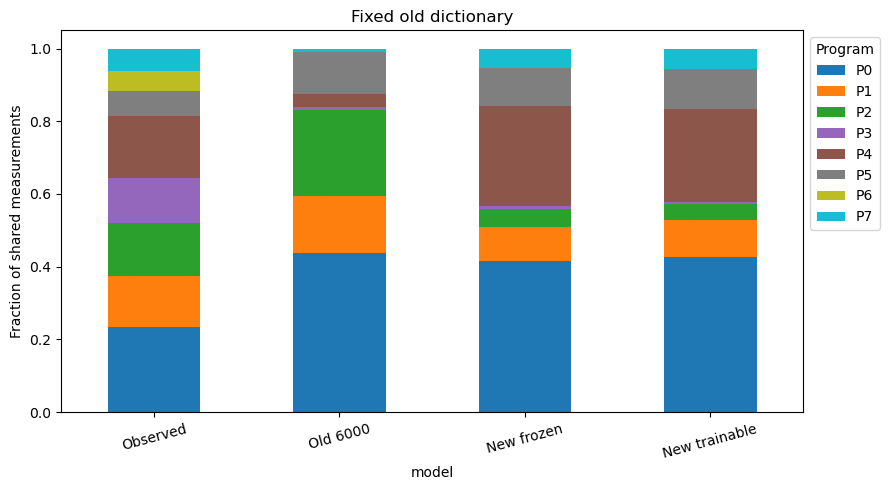

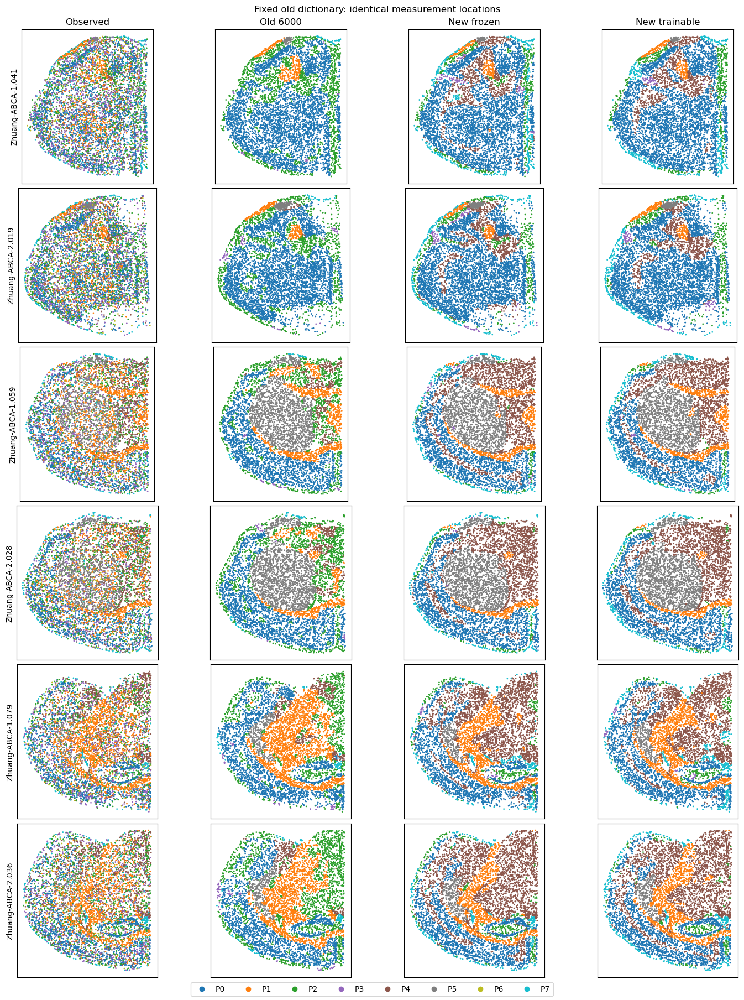

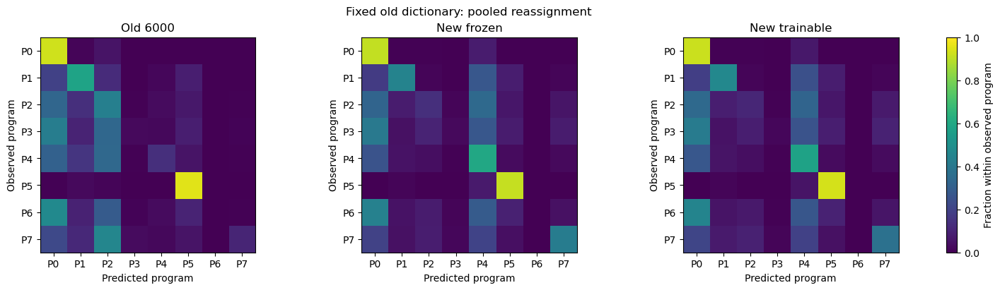

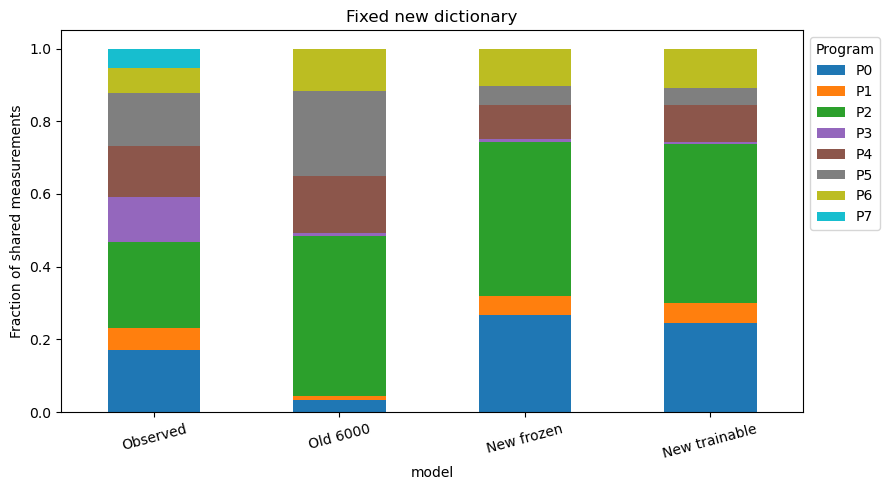

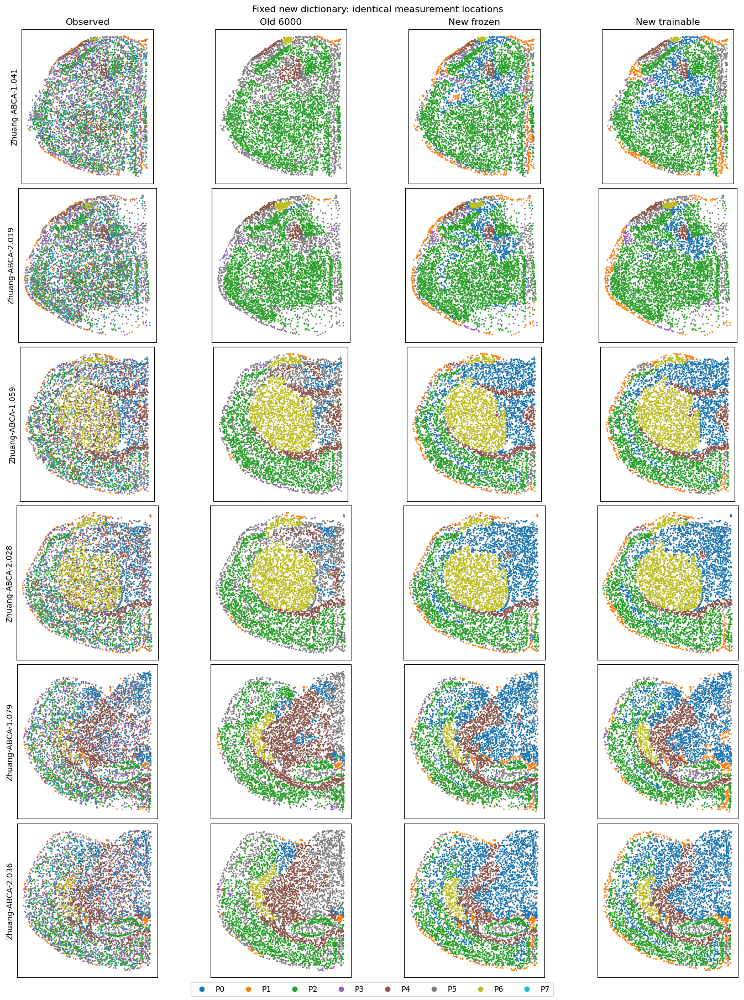

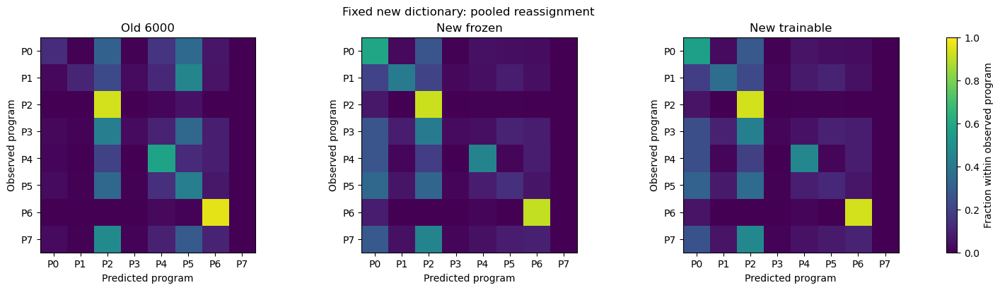

In [20]:
if RUN_EXPRESSION_EXPERIMENT:
    from matplotlib.colors import ListedColormap
    from matplotlib.lines import Line2D
    comparison_models = ['Observed', 'Old 6000', 'New frozen', 'New trainable']
    for dictionary, directory in [('old', old_program_dir), ('new', new_program_dir)]:
        legend = pd.read_csv(directory/'program_legend.csv')
        legend = legend.set_index('program').loc[[f'P{i}' for i in range(len(legend))]].reset_index()
        legend.to_csv(comparison_dir / f'{dictionary}_legend.csv', index=False)
        colors = ListedColormap(legend.color.tolist())
        frame = comparison['fractions'].query('dictionary == @dictionary')
        pooled = frame.groupby(['model', 'program'])[['count', 'n']].sum()
        frequencies = (pooled['count']/pooled['n']).unstack('program')
        frequencies = frequencies.loc[comparison_models, legend.program]
        ax = frequencies.plot.bar(stacked=True, color=legend.color.tolist(), figsize=(9, 5), rot=15)
        ax.set(ylabel='Fraction of shared measurements', title=f'Fixed {dictionary} dictionary')
        ax.legend(title='Program', bbox_to_anchor=(1, 1))
        ax.figure.tight_layout()
        ax.figure.savefig(comparison_figures/f'{dictionary}_fractions.png', dpi=180, bbox_inches='tight')
        plt.show()
        sections = list(comparison['maps'])
        fig, axes = plt.subplots(len(sections), len(comparison_models), figsize=(14, 3*len(sections)),
                                 squeeze=False, constrained_layout=True)
        for row, section in enumerate(sections):
            data = comparison['maps'][section]
            for col, name in enumerate(comparison_models):
                axes[row, col].scatter(*data['xy'].T, c=data[dictionary][name], cmap=colors,
                    vmin=-0.5, vmax=len(legend)-0.5, s=1, rasterized=True)
                axes[row, col].set(aspect='equal', xticks=[], yticks=[], title=name if row == 0 else '')
            axes[row, 0].set_ylabel(section)
        fig.suptitle(f'Fixed {dictionary} dictionary: identical measurement locations')
        fig.legend(handles=[Line2D([], [], marker='o', linestyle='', color=r.color, label=r.program)
                             for r in legend.itertuples()], loc='outside lower center', ncol=len(legend))
        fig.savefig(comparison_figures/f'{dictionary}_matched_maps.png', dpi=180, bbox_inches='tight')
        plt.show()
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
        for ax, name in zip(axes, comparison_models[1:]):
            frame = comparison['confusions'].query('dictionary == @dictionary and model == @name')
            matrix = frame.groupby(['observed_program', 'predicted_program'])['count'].sum().unstack(fill_value=0)
            matrix = matrix.reindex(index=legend.program, columns=legend.program, fill_value=0).to_numpy()
            fractions = matrix/np.maximum(matrix.sum(1, keepdims=True), 1)
            artist = ax.imshow(fractions, vmin=0, vmax=1, cmap='viridis')
            ax.set(title=name, xlabel='Predicted program', ylabel='Observed program',
                   xticks=range(len(legend)), yticks=range(len(legend)))
            ax.set_xticklabels(legend.program)
            ax.set_yticklabels(legend.program)
        fig.suptitle(f'Fixed {dictionary} dictionary: pooled reassignment')
        fig.colorbar(artist, ax=axes, label='Fraction within observed program')
        fig.savefig(comparison_figures/f'{dictionary}_confusion.png', dpi=180, bbox_inches='tight')
        plt.show()


## Optional occupancy after regional synthesis

Run the regional workflow first. Set `ENABLE_OCCUPANCY=True` in regional setup only when ready to study support. A completed regional checkpoint is required. `RUN_JOINT_OCCUPANCY=True` explicitly starts joint training; otherwise a matching completed joint checkpoint loads. The expression objective remains the same multi-scale regional objective, without occupancy gating. Support is a measurement-derived proxy, not histology.


          section  positive  negative  unknown  train_points  validation_points
Zhuang-ABCA-1.041      8382     16268      950         19685               4965
Zhuang-ABCA-2.019      8531     16031     1038         19565               4997
Zhuang-ABCA-1.059     13243     11166     1191         19555               4854
Zhuang-ABCA-2.028     14331     10038     1231         19547               4822
Zhuang-ABCA-1.079     15592      8667     1341         19542               4717
Zhuang-ABCA-2.036     15257      9061     1282         19539               4779
Joint run: 245ba23205a6; device: cuda; trainable parameters: 94,677
Training is opt-in. Review proxy supervision below before enabling it.


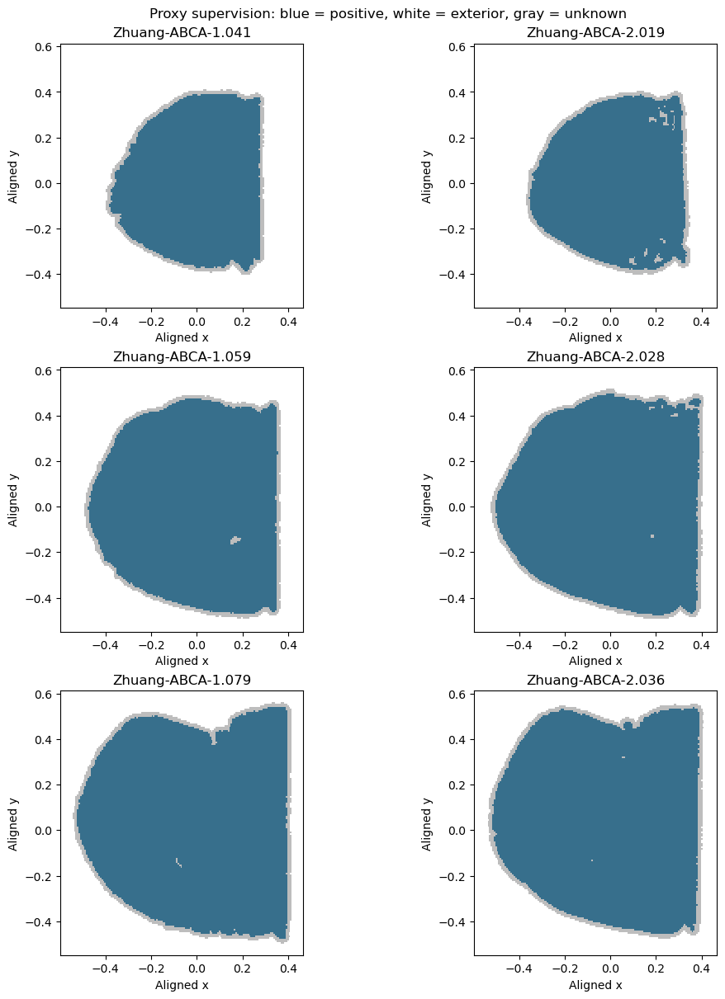

In [21]:
if ENABLE_OCCUPANCY:
    if not reg_ready:
        raise RuntimeError('Complete the regional fit before enabling occupancy')
    from paper.cohort_occupancy import (
        JointOccupancyGenerator, canvas_grid, proxy_support, fit_joint,
        predict_occupancy, occupancy_metrics)
    from paper.program_run_comparison import aligned_xy
    from matplotlib.colors import ListedColormap

    OCC_SOURCE_RUN = REG_SOURCE_RUN
    RUN_JOINT_OCCUPANCY = False
    FORCE_JOINT_RETRAIN = False
    OCC_CFG = dict(
        steps=5000, batch_size=512, occupancy_batch_size=1024, lr=1e-3,
        log_every=250, seed=3107,
        occupancy_weight=1., consistency_weight=0.01, threshold=0.5)
    OCC_MODEL = dict(occupancy_side=16, width=128, occupancy_scale=0.06,
                     min_occupancy_scale=0.005, max_occupancy_scale=0.2)
    OCC_GRID_SIZE = 160
    OCC_CANVAS_PADDING = 0.08
    OCC_POSITIVE_RADIUS_UM = 75.
    OCC_NEGATIVE_RADIUS_UM = 175.
    OCC_VALIDATION_FRACTION = 0.2
    OCC_BLOCK_PIXELS = 8
    OCC_ALPHAS = [0., 0.25, 0.5, 0.75, 1.]
    OCC_PLOT_GENES = ['Slc17a7', 'Mog']

    occ_processed = data_directory()/'processed'
    occ_source = occ_processed/'zhuang_conditional_synthesis'/OCC_SOURCE_RUN
    occ_source_checkpoint = PROJECT_ROOT/'notebooks'/'checkpoints'/'zhuang_conditional_synthesis'/OCC_SOURCE_RUN/'frozen'/'generator_latest.pt'
    occ_manifest = json.loads((occ_source/'manifest.json').read_text())
    occ_settings = occ_manifest['settings']
    with torch.serialization.safe_globals([torch.torch_version.TorchVersion]):
        occ_saved = torch.load(occ_source_checkpoint, map_location='cpu', weights_only=True)
    if occ_saved['decoder_variant'] != 'frozen' or occ_saved['provenance']['settings'] != occ_settings:
        raise ValueError('Occupancy source must be the matching archived frozen-decoder generator')
    occ_genes = np.asarray(occ_saved['gene_ids'], dtype=str)
    occ_gene_archive = occ_source/'frozen'/'field_level0_alpha0.00.npz'
    with np.load(occ_gene_archive, allow_pickle=False) as saved:
        if not np.array_equal(saved['gene_ids'], occ_genes):
            raise ValueError('Exported gene metadata differs from the source checkpoint')
        occ_symbols = saved['gene_symbols'].copy()
    occ_alignment = pd.read_csv(occ_source/'alignment.csv').set_index('section')
    occ_records, occ_sources = [], [occ_source_checkpoint, occ_source/'manifest.json', occ_source/'alignment.csv', occ_gene_archive]
    for pair in occ_settings['pairs']:
        for section in pair:
            path = occ_source/f'{section}.npz'
            with np.load(path, allow_pickle=False) as saved:
                if not np.array_equal(saved['gene_ids'], occ_genes) or str(saved['expression_kind']) != 'log2':
                    raise ValueError('Archived gene order or expression representation differs')
                raw = saved['xy_raw'].copy()
                occ_records.append(dict(section=section, xy_raw=raw, xy=aligned_xy(raw, occ_alignment.loc[section]),
                    expression=saved['expression'].copy(), measurement_ids=saved['measurement_ids'].copy(),
                    condition=(int(saved['level']), float(saved['donor_index']))))
            occ_sources.append(path)
    occ_common_scales = occ_alignment.common_scale.to_numpy()
    if not np.allclose(occ_common_scales, occ_common_scales[0]):
        raise ValueError('Occupancy requires the saved common isotropic coordinate scale')
    occ_um_per_unit = float(occ_common_scales[0]*1000)
    occ_points = np.concatenate([r['xy'] for r in occ_records])
    occ_lower = occ_points.min(0)-OCC_CANVAS_PADDING
    occ_upper = occ_points.max(0)+OCC_CANVAS_PADDING
    occ_grid = canvas_grid(occ_lower, occ_upper, OCC_GRID_SIZE)
    occ_targets = {r['section']: proxy_support(r['xy'], occ_grid, OCC_GRID_SIZE,
        positive_radius=OCC_POSITIVE_RADIUS_UM/occ_um_per_unit,
        negative_radius=OCC_NEGATIVE_RADIUS_UM/occ_um_per_unit,
        validation_fraction=OCC_VALIDATION_FRACTION, block_pixels=OCC_BLOCK_PIXELS,
        seed=OCC_CFG['seed']) for r in occ_records}
    occ_ae_shell = GeneProfileAutoencoder(len(occ_genes), occ_settings['ae_hidden'], occ_settings['latent_dim'])
    occ_base = CohortSplatGenerator(occ_saved['initialization'], occ_ae_shell.decoder,
        num_levels=len(occ_settings['pairs']), embedding_dim=occ_settings['embedding_dim'],
        width=occ_settings['generator_width'], slot_dim=occ_settings['slot_dim'],
        kernel_sharpness=occ_settings['kernel_sharpness'], init_log_scale=occ_settings['init_log_scale'],
        min_scale=occ_settings['min_scale'], max_scale=occ_settings['max_scale'])
    occ_base.load_state_dict(reg_model.state_dict())
    occ_sources.append(REG_CHECKPOINT)
    occ_base.eval().requires_grad_(False)
    OCC_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.manual_seed(OCC_CFG['seed'])
    occ_model = JointOccupancyGenerator(occ_base, occ_lower, occ_upper, **OCC_MODEL).to(OCC_DEVICE)
    occ_sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
    occ_provenance = dict(regional_run=REG_RUN, regional_provenance=reg_provenance, source_run=OCC_SOURCE_RUN, config=OCC_CFG, model=OCC_MODEL,
        grid_size=OCC_GRID_SIZE, padding=OCC_CANVAS_PADDING,
        positive_radius_um=OCC_POSITIVE_RADIUS_UM, negative_radius_um=OCC_NEGATIVE_RADIUS_UM,
        um_per_model_unit=occ_um_per_unit, validation_fraction=OCC_VALIDATION_FRACTION,
        block_pixels=OCC_BLOCK_PIXELS, canvas_lower=occ_lower.tolist(), canvas_upper=occ_upper.tolist(),
        source_hashes={str(path): occ_sha(path) for path in occ_sources},
        code_hashes={name: occ_sha(PROJECT_ROOT/name) for name in [
            'paper/cohort_occupancy.py', 'paper/cohort_regional_synthesis.py', 'paper/cohort_field_synthesis.py',
            'paper/conditional_field.py', 'spatsplat/models.py']},
        reference='coordinate-derived proxy, not histological tissue',
        torch_version=str(torch.__version__))
    OCC_RUN = hashlib.sha256(json.dumps(occ_provenance, sort_keys=True).encode()).hexdigest()[:12]
    OCC_OUTPUT = occ_processed/'zhuang_joint_occupancy'/OCC_RUN
    OCC_FIGURES = PROJECT_ROOT/'figures'/'zhuang_joint_occupancy'/OCC_RUN
    OCC_CHECKPOINTS = PROJECT_ROOT/'notebooks'/'checkpoints'/'zhuang_joint_occupancy'/OCC_RUN
    OCC_CHECKPOINT = OCC_CHECKPOINTS/'joint_generator.pt'
    # These roots are separate from every archived expression-only run.
    for directory in [OCC_OUTPUT, OCC_FIGURES, OCC_CHECKPOINTS]:
        directory.mkdir(parents=True, exist_ok=True)
    (OCC_OUTPUT/'manifest.json').write_text(json.dumps(occ_provenance, indent=2))
    np.savez_compressed(OCC_OUTPUT/'support_targets.npz', grid=occ_grid,
        **{r['section']+'_'+key: occ_targets[r['section']][key]
           for r in occ_records for key in ['labels', 'train', 'validation', 'block_ids']})
    occ_audit = pd.DataFrame([dict(section=r['section'], positive=int((t['labels'] == 1).sum()),
        negative=int((t['labels'] == 0).sum()), unknown=int((t['labels'] < 0).sum()),
        train_points=len(t['train']), validation_points=len(t['validation']))
        for r in occ_records for t in [occ_targets[r['section']]]])
    print(occ_audit.to_string(index=False))
    print(f'Joint run: {OCC_RUN}; device: {OCC_DEVICE}; trainable parameters: {sum(p.numel() for p in occ_model.parameters() if p.requires_grad):,}')
    print('Training is opt-in. Review proxy supervision below before enabling it.')
    occ_extent = (occ_lower[0], occ_upper[0], occ_lower[1], occ_upper[1])
    fig, axes = plt.subplots(len(occ_settings['pairs']), 2, figsize=(10, 4*len(occ_settings['pairs'])), squeeze=False, constrained_layout=True)
    for ax, r in zip(axes.flat, occ_records):
        labels = occ_targets[r['section']]['labels'].reshape(OCC_GRID_SIZE, OCC_GRID_SIZE)
        ax.imshow(labels, origin='lower', extent=occ_extent, cmap=ListedColormap(['#bdbdbd', '#ffffff', '#376f8c']),
                  vmin=-1.5, vmax=1.5, interpolation='nearest')
        ax.set(title=r['section'], xlabel='Aligned x', ylabel='Aligned y')
    fig.suptitle('Proxy supervision: blue = positive, white = exterior, gray = unknown')
    fig.savefig(OCC_FIGURES/'proxy_support_preview.png', dpi=180, bbox_inches='tight')
    plt.show()

else:
    print('Occupancy disabled; finish regional expression synthesis first.')


Loaded completed joint checkpoint. No neural training ran.


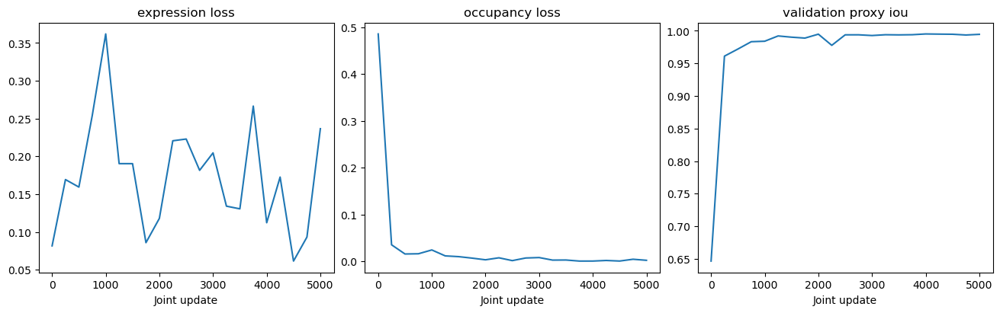

In [22]:
if ENABLE_OCCUPANCY:
    # A matching completed run loads by default. No automatic training on a cache miss.
    occ_complete = False
    if OCC_CHECKPOINT.exists():
        occ_payload = torch.load(OCC_CHECKPOINT, map_location=OCC_DEVICE, weights_only=True)
        if occ_payload['provenance'] != occ_provenance:
            raise ValueError('Joint checkpoint provenance mismatch')
        occ_complete = bool(occ_payload.get('complete', False))

    if occ_complete and not (RUN_JOINT_OCCUPANCY and FORCE_JOINT_RETRAIN):
        occ_model.load_state_dict(occ_payload['state_dict'])
        occ_history = pd.DataFrame(occ_payload['history'])
        occ_ready = True
        print('Loaded completed joint checkpoint. No neural training ran.')
    elif RUN_JOINT_OCCUPANCY:
        torch.manual_seed(OCC_CFG['seed'])
        # Always restart a deliberately requested fit from the archived source, not the current notebook state.
        occ_model = JointOccupancyGenerator(occ_base, occ_lower, occ_upper, **OCC_MODEL).to(OCC_DEVICE)
        def save_joint_checkpoint(current, history, complete=False):
            payload = dict(state_dict={k: v.detach().cpu() for k, v in current.state_dict().items()},
                           provenance=occ_provenance, history=history, complete=complete)
            temporary = OCC_CHECKPOINT.with_suffix('.tmp')
            torch.save(payload, temporary)
            temporary.replace(OCC_CHECKPOINT)
            pd.DataFrame(history).to_csv(OCC_OUTPUT/'joint_history.csv', index=False)
        print(f'Joint training: {OCC_CFG["steps"]} updates. Expression decoder is frozen; both emitted branches learn.', flush=True)
        occ_history = fit_joint(occ_model, occ_records, occ_grid, occ_targets, OCC_CFG, expression_objective=reg_objective,
                               on_checkpoint=save_joint_checkpoint)
        save_joint_checkpoint(occ_model, occ_history.to_dict('records'), complete=True)
        occ_ready = True
    else:
        occ_ready = False
        state = 'incomplete' if OCC_CHECKPOINT.exists() else 'missing'
        print(f'Joint checkpoint is {state}. No neural training ran. Set RUN_JOINT_OCCUPANCY=True and rerun setup/training to fit it.')
    if occ_ready:
        occ_model.eval()
        occ_history.to_csv(OCC_OUTPUT/'joint_history.csv', index=False)
        fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
        for ax, key in zip(axes, ['expression_loss', 'occupancy_loss', 'validation_proxy_iou']):
            ax.plot(occ_history.step, occ_history[key])
            ax.set(xlabel='Joint update', title=key.replace('_', ' '))
        fig.savefig(OCC_FIGURES/'joint_training.png', dpi=180, bbox_inches='tight')
        plt.show()

else:
    print('Occupancy disabled; finish regional expression synthesis first.')


Occupancy scores use confident proxy labels; unknown regions are excluded:
          section            split     n      bce     brier  proxy_iou  proxy_dice  positive_recall  exterior_false_positive_fraction
Zhuang-ABCA-1.041            train 19685  0.00185 0.0002755     0.9992      0.9996           0.9995                         0.0001516
Zhuang-ABCA-1.041       validation  4965  0.01165  0.003314       0.99       0.995           0.9915                         0.0009753
Zhuang-ABCA-1.041 all_measurements 12473      NaN       NaN        NaN         NaN           0.9992                               NaN
Zhuang-ABCA-2.019            train 19565 0.001583 0.0002046     0.9995      0.9998           0.9998                         0.0001536
Zhuang-ABCA-2.019       validation  4997  0.01155  0.002928     0.9914      0.9957           0.9914                                 0
Zhuang-ABCA-2.019 all_measurements 13825      NaN       NaN        NaN         NaN           0.9993                      

profile_cosine  expression_mae  \
width_um method                                                      
50       Regional before occupancy          0.8299         0.09079   
         Regional plus occupancy            0.8349         0.09031   
         Spatial shuffle (oracle)           0.4701          0.1491   
         Training mean                      0.6528          0.1242   
100      Regional before occupancy          0.8767         0.07398   
         Regional plus occupancy            0.8819         0.07322   
         Spatial shuffle (oracle)           0.5744          0.1279   
         Training mean                      0.7275          0.1027   
200      Regional before occupancy          0.9348         0.04938   
         Regional plus occupancy             0.941         0.04796   
         Spatial shuffle (oracle)           0.6605          0.1024   
         Training mean                      0.7792         0.08188   

                                    profile_l1   frechet  
width_um method                                           
50       Regional before occupancy      0.7631 8.994e-05  
         Regional plus occupancy        0.7561 9.565e-05  
         Spatial shuffle (oracle)        1.248 8.674e-19  
         Training mean                    1.04  0.002095  
100      Regional before occupancy      0.6176 4.644e-05  
         Regional plus occupancy         0.609 4.422e-05  
         Spatial shuffle (oracle)        1.062 1.807e-19  
         Training mean                  0.8548  0.001393  
200      Regional before occupancy      0.4185 1.823e-05  
         Regional plus occupancy         0.405 1.128e-05  
         Spatial shuffle (oracle)       0.8588         0  
         Training mean                  0.6866  0.001132

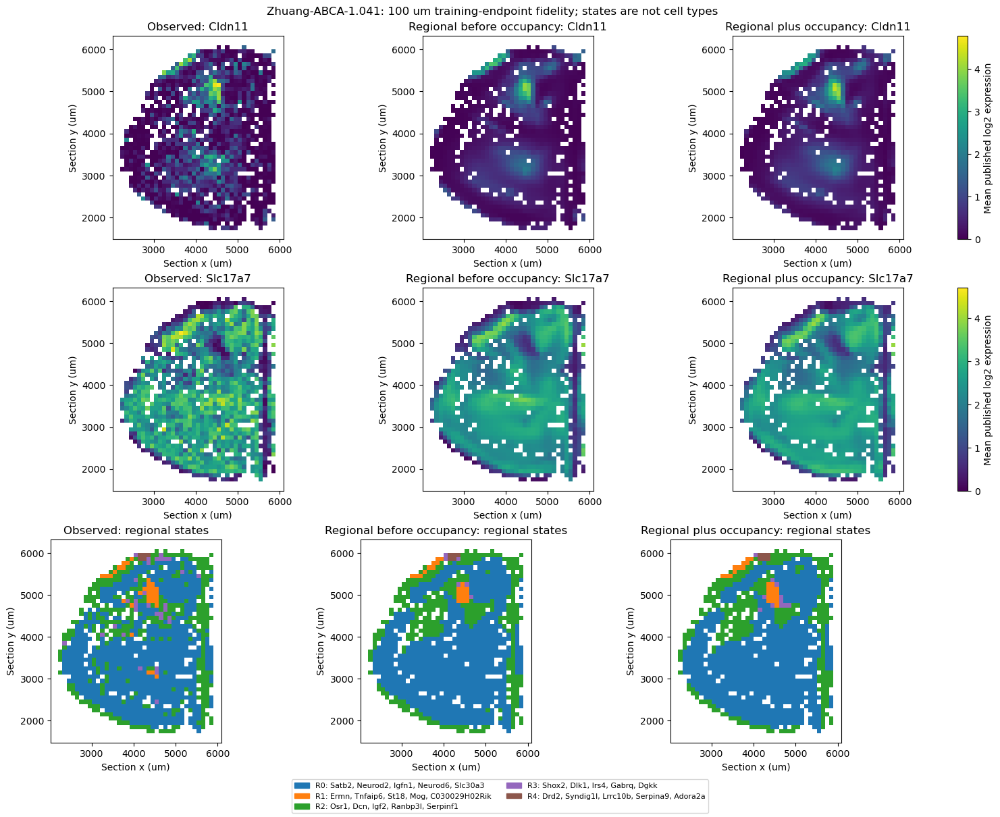

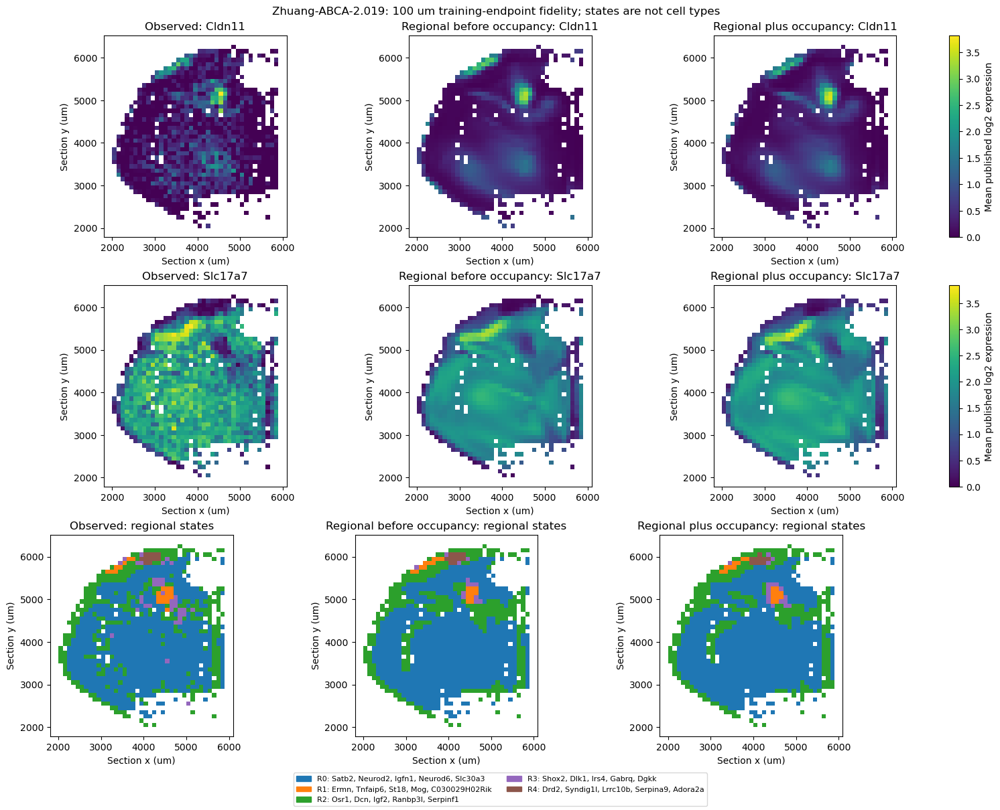

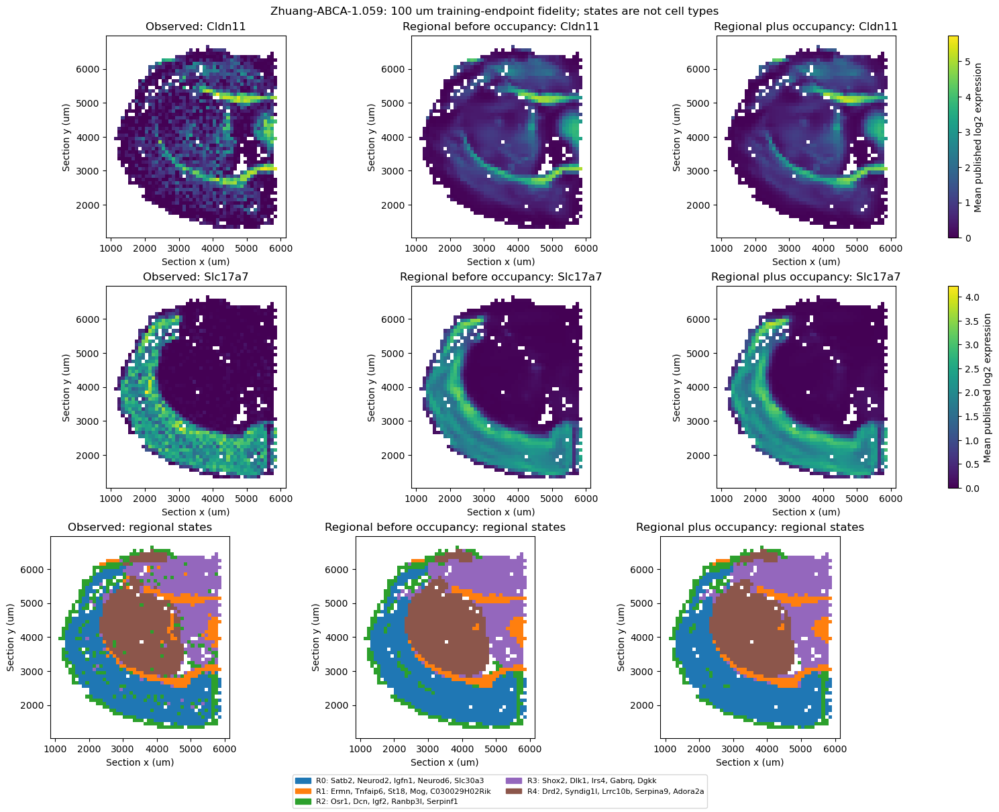

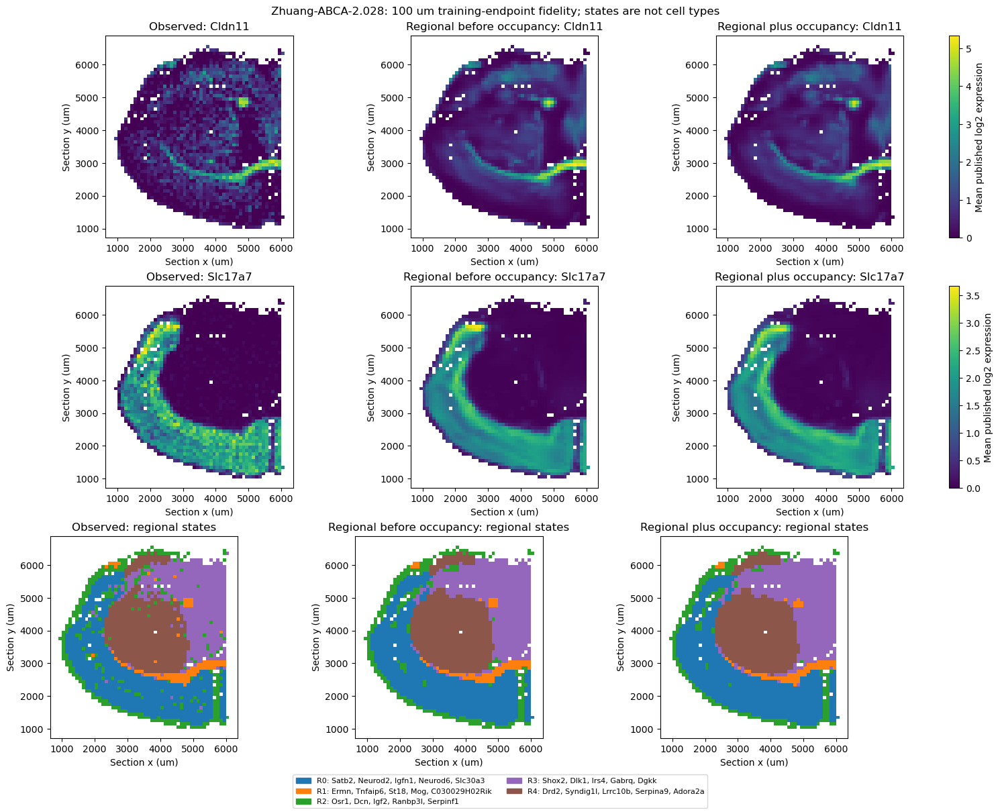

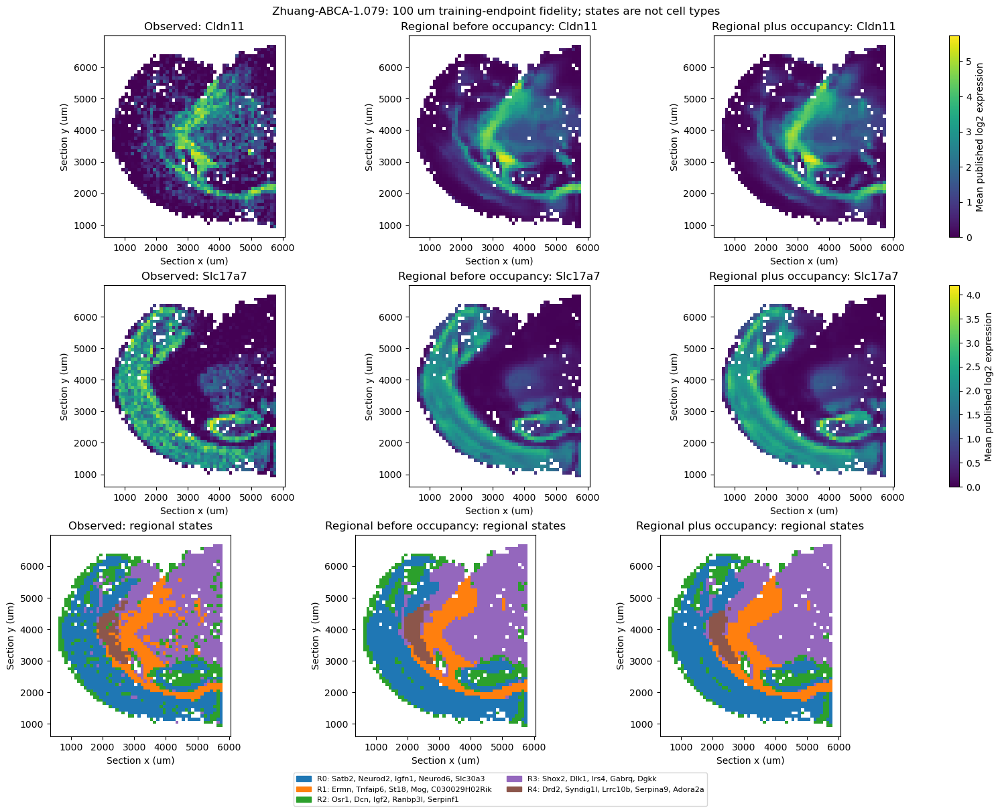

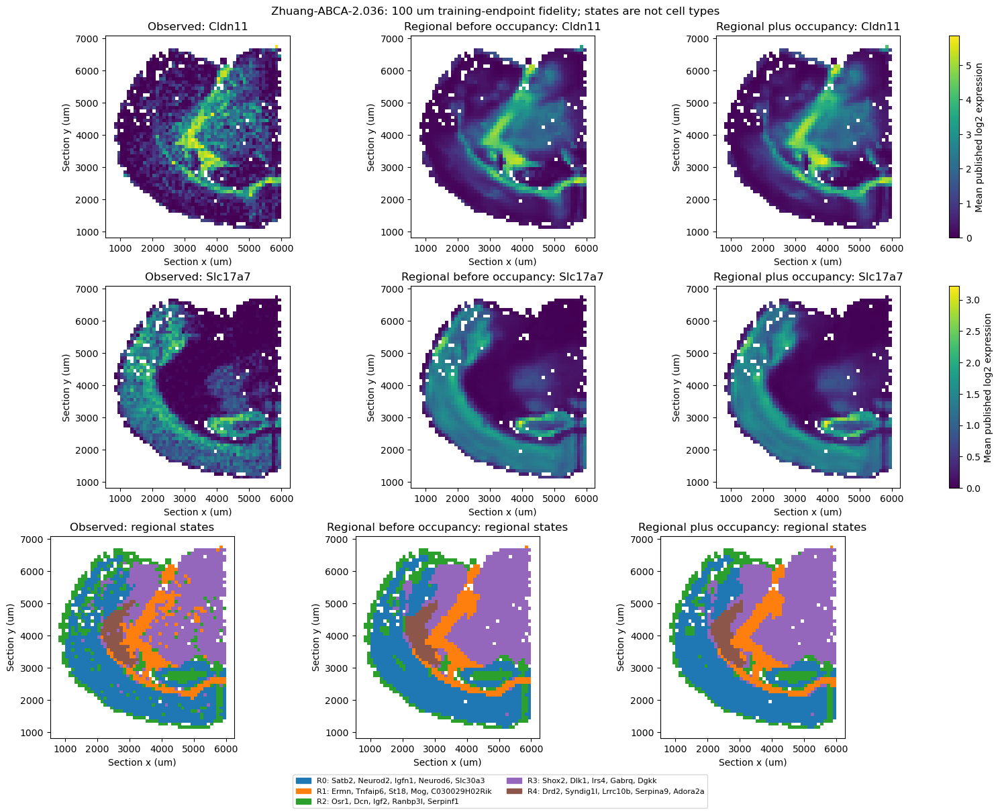

In [23]:
if ENABLE_OCCUPANCY:
    if occ_ready:
        occ_rows, occ_expr_rows = [], []
        occ_endpoint_predictions = {}
        for r in occ_records:
            target = occ_targets[r['section']]
            probability = predict_occupancy(occ_model, occ_grid, r['condition'])
            for split in ['train', 'validation']:
                occ_rows.append(dict(section=r['section'], split=split,
                    **occupancy_metrics(probability, target['labels'], target[split], OCC_CFG['threshold'])))
            measurement_probability = predict_occupancy(occ_model, r['xy'], r['condition'])
            after = predict_field(occ_model, r['xy'], r['condition'])
            before = predict_field(occ_model.base, r['xy'], r['condition'])
            for name, values in [('Archived frozen synthesis', before), ('Joint expression (unmasked)', after)]:
                occ_expr_rows.append(dict(section=r['section'], method=name,
                    **field_metrics(values, r['expression'])))
            occ_endpoint_predictions[r['section']] = after
            np.savez_compressed(OCC_OUTPUT/f'{r["section"]}_endpoint.npz',
                expression=after, measurement_ids=r['measurement_ids'], gene_ids=occ_genes,
                xy=r['xy'], occupancy_at_measurements=measurement_probability,
                occupancy_probability=probability, binary_mask=probability >= OCC_CFG['threshold'])
            occ_rows.append(dict(section=r['section'], split='all_measurements',
                n=len(r['xy']), positive_recall=float(np.mean(measurement_probability >= OCC_CFG['threshold']))))
        occ_metrics = pd.DataFrame(occ_rows)
        occ_expression_metrics = pd.DataFrame(occ_expr_rows)
        occ_metrics.to_csv(OCC_OUTPUT/'occupancy_metrics.csv', index=False)
        occ_expression_metrics.to_csv(OCC_OUTPUT/'expression_metrics.csv', index=False)
        print('Occupancy scores use confident proxy labels; unknown regions are excluded:')
        print(occ_metrics.to_string(index=False, float_format=lambda x: f'{x:.4g}'))
        print('Expression is evaluated at ALL observations, without occupancy gating:')
        print(occ_expression_metrics.to_string(index=False, float_format=lambda x: f'{x:.4g}'))
        occ_gene_indices = []
        for gene in OCC_PLOT_GENES:
            indices = np.flatnonzero(occ_symbols == gene)
            if len(indices) != 1:
                raise ValueError(f'Expected one plotting gene match: {gene}')
            occ_gene_indices.append(int(indices[0]))
        occ_renders = {}
        for level in range(len(occ_settings['pairs'])):
            for alpha in OCC_ALPHAS:
                condition = (level, alpha)
                probability = predict_occupancy(occ_model, occ_grid, condition)
                # The whole fixed canvas is rendered. No real tissue mask is applied.
                values = predict_field(occ_model, occ_grid, condition)[:, occ_gene_indices]
                binary = probability >= OCC_CFG['threshold']
                occ_renders[level, alpha] = dict(probability=probability, binary=binary, expression=values)
                expression_parameters = export_field(occ_model, condition)
                with torch.no_grad():
                    occupancy_parameters = {key: value.cpu().numpy()
                        for key, value in occ_model.emit_occupancy(condition).items()}
                np.savez_compressed(OCC_OUTPUT/f'emitted_level{level}_alpha{alpha:.2f}.npz',
                    **expression_parameters, **{'occupancy_'+key: value for key, value in occupancy_parameters.items()},
                    gene_ids=occ_genes, kernel_sharpness=occ_settings['kernel_sharpness'],
                    canvas_lower=occ_lower, canvas_upper=occ_upper, binary_threshold=OCC_CFG['threshold'])
                np.savez_compressed(OCC_OUTPUT/f'render_level{level}_alpha{alpha:.2f}.npz',
                    grid=occ_grid, occupancy_probability=probability, binary_mask=binary,
                    expression=values, gene_symbols=np.asarray(OCC_PLOT_GENES))
        print('Exported standalone expression and occupancy primitives, soft probabilities and binary masks.')
    else:
        print('Evaluation skipped: load or explicitly train a completed joint model first.')

    if occ_ready:
        occ_regional, occ_regional_metrics = evaluate_regional_models(
            {'Regional before occupancy': reg_model, 'Regional plus occupancy': occ_model}, OCC_OUTPUT)
        display(occ_regional_metrics.groupby(['width_um', 'method'])[
            ['profile_cosine', 'expression_mae', 'profile_l1', 'frechet']].mean())
        plot_regional_comparison(occ_regional, OCC_FIGURES)

else:
    print('Occupancy disabled; finish regional expression synthesis first.')


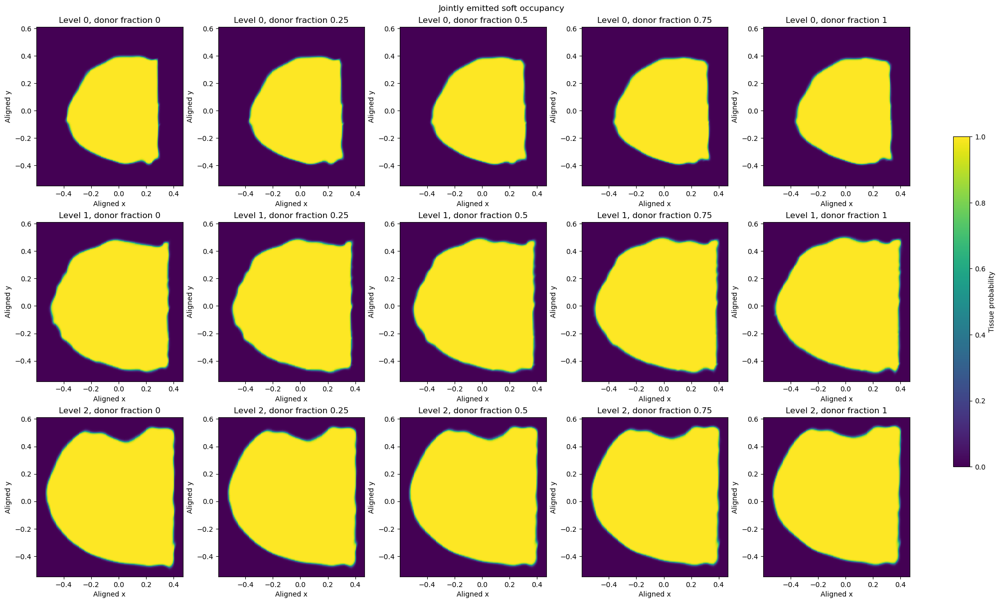

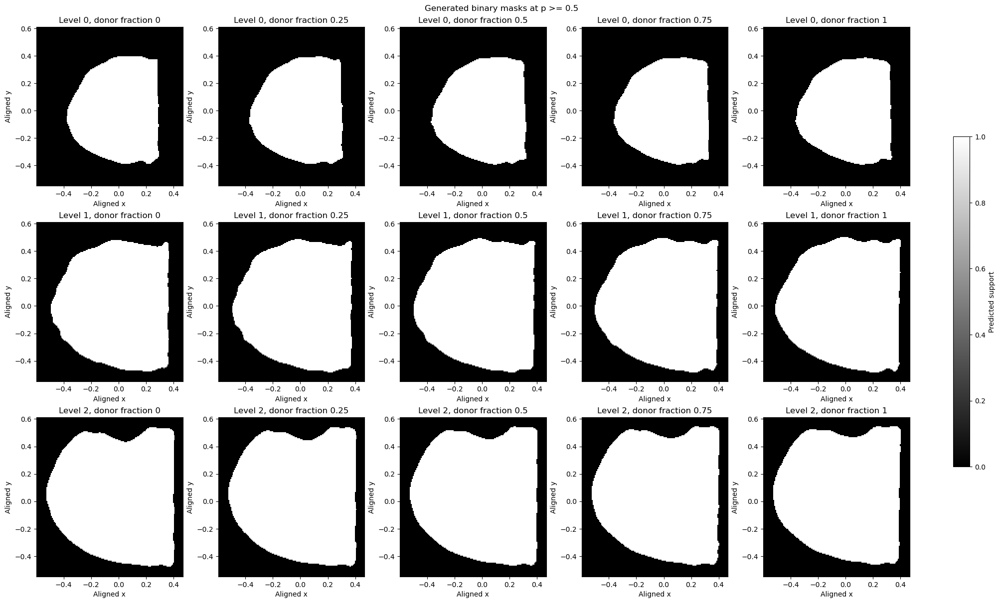

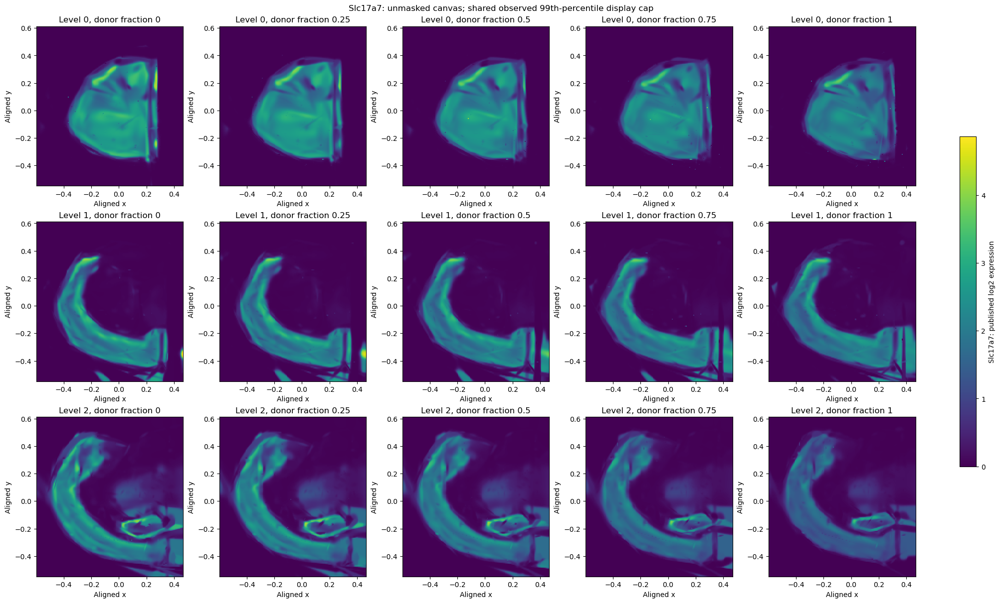

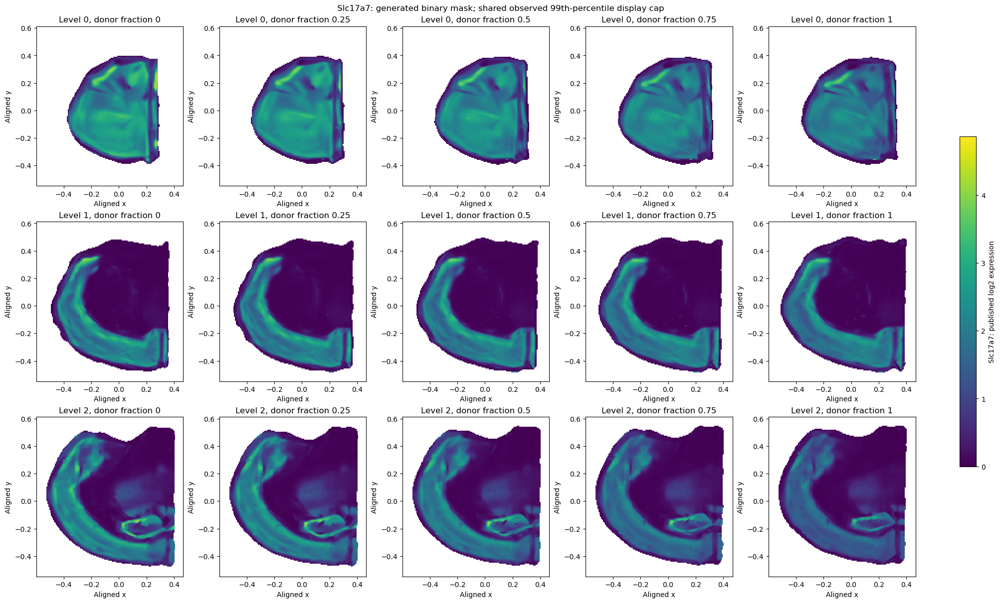

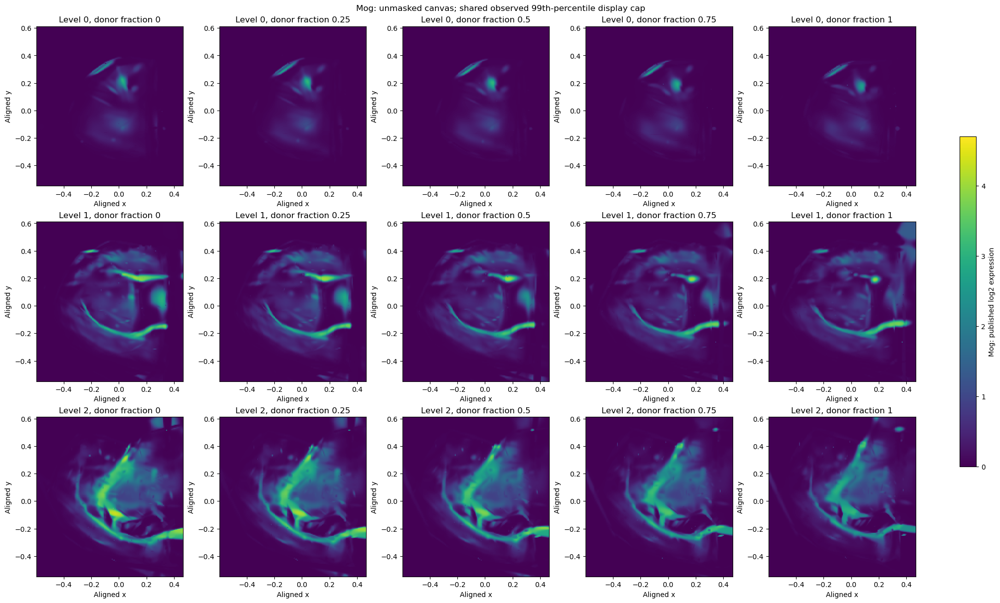

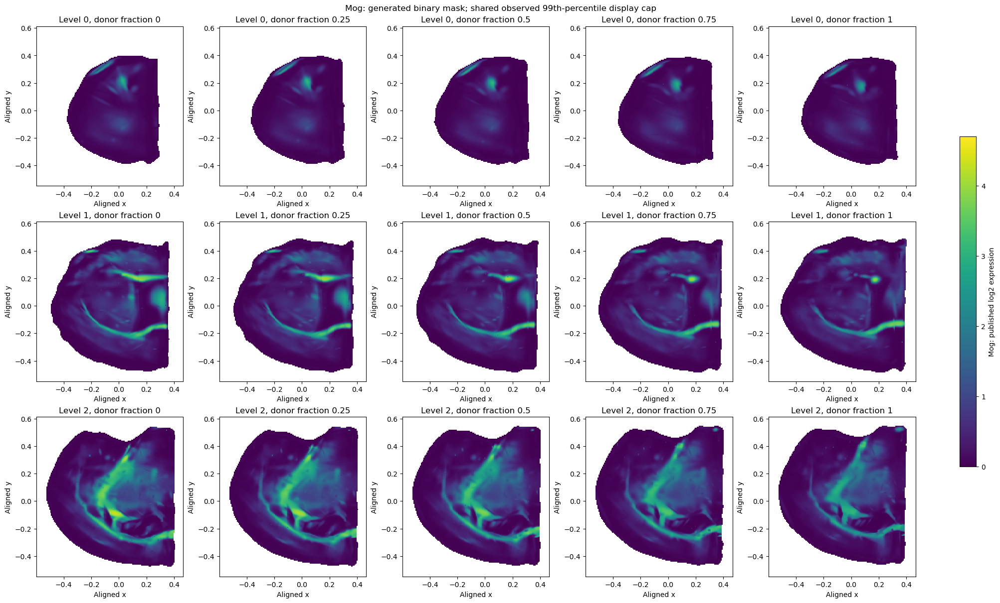

In [24]:
if ENABLE_OCCUPANCY:
    if occ_ready:
        nlevels = len(occ_settings['pairs'])
        for kind in ['probability', 'binary']:
            fig, axes = plt.subplots(nlevels, len(OCC_ALPHAS), figsize=(4*len(OCC_ALPHAS), 4*nlevels),
                                     squeeze=False, constrained_layout=True)
            for level in range(nlevels):
                for col, alpha in enumerate(OCC_ALPHAS):
                    ax = axes[level, col]
                    values = occ_renders[level, alpha][kind].reshape(OCC_GRID_SIZE, OCC_GRID_SIZE)
                    artist = ax.imshow(values, origin='lower', extent=occ_extent, interpolation='nearest',
                                       cmap='viridis' if kind == 'probability' else 'gray', vmin=0, vmax=1)
                    ax.set(title=f'Level {level}, donor fraction {alpha:.2g}', xlabel='Aligned x', ylabel='Aligned y')
            fig.colorbar(artist, ax=axes.ravel().tolist(), label='Tissue probability' if kind == 'probability' else 'Predicted support', shrink=0.6)
            fig.suptitle('Jointly emitted soft occupancy' if kind == 'probability' else f'Generated binary masks at p >= {OCC_CFG["threshold"]:.2g}')
            fig.savefig(OCC_FIGURES/f'emitted_occupancy_{kind}.png', dpi=180, bbox_inches='tight')
            plt.show()
        for j, gene in enumerate(OCC_PLOT_GENES):
            vmax = max(float(np.quantile(r['expression'][:, occ_gene_indices[j]], 0.99)) for r in occ_records) or 1
            for mask_output in [False, True]:
                fig, axes = plt.subplots(nlevels, len(OCC_ALPHAS), figsize=(4*len(OCC_ALPHAS), 4*nlevels),
                                         squeeze=False, constrained_layout=True)
                for level in range(nlevels):
                    for col, alpha in enumerate(OCC_ALPHAS):
                        rendered = occ_renders[level, alpha]
                        values = rendered['expression'][:, j].reshape(OCC_GRID_SIZE, OCC_GRID_SIZE)
                        if mask_output:
                            values = np.ma.masked_where(~rendered['binary'].reshape(OCC_GRID_SIZE, OCC_GRID_SIZE), values)
                        ax = axes[level, col]
                        artist = ax.imshow(values, origin='lower', extent=occ_extent, interpolation='nearest',
                                           cmap='viridis', vmin=0, vmax=vmax)
                        ax.set(title=f'Level {level}, donor fraction {alpha:.2g}', xlabel='Aligned x', ylabel='Aligned y')
                fig.colorbar(artist, ax=axes.ravel().tolist(), label=f'{gene}: published log2 expression', shrink=0.6)
                mode = 'generated binary mask' if mask_output else 'unmasked canvas'
                fig.suptitle(f'{gene}: {mode}; shared observed 99th-percentile display cap')
                fig.savefig(OCC_FIGURES/f'{gene}_{"masked" if mask_output else "unmasked"}.png', dpi=180, bbox_inches='tight')
                plt.show()
    else:
        print('Joint occupancy plots skipped: no completed model is loaded.')

else:
    print('Occupancy disabled; finish regional expression synthesis first.')


### What this experiment establishes

- This is **joint warm-start training**, not occupancy added as a post-processing mask. New expression geometry/profile residuals, occupancy geometry/strengths and shared condition embeddings learn in one optimization. Expression supervision never depends on whether occupancy is predicted positive.
- The decoder and archived expression model stay fixed; the new residual branch can modify every emitted expression primitive. The warm-start expression objective uses the same multi-scale regional MAE + cosine + log-total terms as the primary regional experiment. It does not rerun the old curriculum or freeze the new geometry during refinement.
- Occupancy uses a separate positive Gaussian basis plus a background logit, not normalized expression responsibilities. Occupancy is not inferred from low expression. Both sets of emitted primitives are exported.
- A small center-consistency loss encourages expression splats to lie inside predicted support. Occupancy labels anchor that prediction; the weight is explicit. The old point-distance and off-tissue-expression losses are not duplicated in this experiment.
- Threshold 0.5 is fixed, not selected using training/test performance. Exported soft probabilities are retained. Binary masks clip display only; probabilities do not attenuate gene expression at the boundary.
- Train/validation occupancy scores refer to spatially blocked grid labels within the same six training sections. They do not establish unseen-specimen anatomy or calibrated uncertainty. All expression endpoint scores remain in-sample.
- Reference support is a **measurement-derived proxy**. Unknown interior gaps and boundary bands are neither positive nor negative training targets. Proxy IoU/Dice exclude them and must not be described as histological mask accuracy.
- The generator sees only a condition when emitting a field. The canvas is fixed from training geometry and padding; no endpoint or held-out support mask is supplied at inference. Synthetic intermediates have no real reference masks.
- Compare the primary unmasked regional metrics/maps and secondary measurement metrics before/after joint training, predicted support at observed measurements, and exterior false positives. A mask that conceals poor expression without preserving tissue coverage is not a success.
- Completed checkpoints load by default. Missing/incomplete checkpoints do **not** trigger training. Interrupted fits restart only after an explicit training request; they are not silently treated as completed runs.

New outputs use `processed/zhuang_joint_occupancy/<run>/`, root `figures/zhuang_joint_occupancy/<run>/` and `notebooks/checkpoints/zhuang_joint_occupancy/<run>/`. Previous expression-only archives are untouched.
